In [2]:
# =========================================================
# 1. INPUT FILES
# =========================================================

import pandas as pd
import numpy as np
import pymrio
from pathlib import Path

IAM_file = Path(
    r"C:\Users\menne\Documents\Master\Thesis\Data\MRIO\Exiobase\Emissions\Kopie van IAM_data.csv"
)

region_file = Path(
    r"C:\Users\menne\Documents\Master\Thesis\Data\MRIO\Exiobase\regions_EXIOBASE.csv"
)

EXIOBASE_file = Path(
    r"C:\Users\menne\Documents\Master\Thesis\Data\MRIO\Exiobase\IOT_2020_pxp.zip"
)

df_IAM = pd.read_csv(
    IAM_file,
    sep=";",
    encoding="utf-8-sig",
    low_memory=False
)

df_regions = pd.read_csv(
    region_file,
    sep=";",
    encoding="utf-8-sig",
    low_memory=False
)

exio = pymrio.parse_exiobase3(EXIOBASE_file)

print("IAM rows:", len(df_IAM))
print("EXIOBASE regions:", len(exio.get_regions()))
print("EXIOBASE products:", len(exio.get_sectors()))


IAM rows: 470011
EXIOBASE regions: 49
EXIOBASE products: 200


In [3]:
# =========================================================
# 2. EXIOBASE 2020 DIRECT GHG VECTOR e_2020
# =========================================================

F = exio.air_emissions.F.copy()

labels = pd.Series(
    F.index.astype(str),
    index=F.index
)

co2_rows = (
    labels.str.startswith("CO2 -")
    | labels.str.startswith("CO2_bio -")
)
ch4_rows = labels.str.startswith("CH4 -")
n2o_rows = labels.str.startswith("N2O -")
sf6_rows = labels.eq("SF6 - air")
hfc_rows = labels.eq("HFC - air")
pfc_rows = labels.eq("PFC - air")

GWP_CH4 = 28
GWP_N2O = 265
GWP_SF6 = 23500

e_2020 = (
    F.loc[co2_rows].sum(axis=0)
    + GWP_CH4 * F.loc[ch4_rows].sum(axis=0)
    + GWP_N2O * F.loc[n2o_rows].sum(axis=0)
    + GWP_SF6 * F.loc[sf6_rows].sum(axis=0)
    + F.loc[hfc_rows].sum(axis=0)
    + F.loc[pfc_rows].sum(axis=0)
)

e_2020.name = "e_2020"

print(
    "Negative EXIOBASE direct-GHG nodes:",
    int((e_2020 < 0).sum())
)


Negative EXIOBASE direct-GHG nodes: 0


In [4]:
# =========================================================
# 3. EXIOBASE 2020 EMISSION INTENSITY
#
# S_2020 = e_2020 / x_2020
# =========================================================

x_2020 = exio.x.iloc[:, 0].copy()
x_2020.name = "x_2020"

e_2020 = e_2020.reindex(x_2020.index)

if e_2020.isna().any():
    raise ValueError(
        "EXIOBASE e_2020 and x_2020 do not align."
    )

# ---------------------------------------------------------
# Structural zero-output nodes
# ---------------------------------------------------------
# EXIOBASE contains region-product combinations with x_2020 = 0.
# For such nodes e/x is undefined. Some of these nodes can still
# contain extremely small non-zero environmental-extension values
# (numerical residuals), as seen for e.g. AT - Paddy rice.
#
# Because there is no economic output to which these emissions can
# be attributed, no finite direct emission intensity can be defined.
# We therefore set S_2020 = 0 for all x_2020 = 0 nodes, while
# explicitly reporting the emissions that are discarded by this
# treatment.

zero_output = x_2020.eq(0)

zero_output_emissions = e_2020.loc[zero_output]

zero_output_abs_total = zero_output_emissions.abs().sum()
total_abs_emissions = e_2020.abs().sum()

zero_output_share = np.where(
    total_abs_emissions > 0,
    zero_output_abs_total / total_abs_emissions,
    np.nan
)

print(
    "EXIOBASE structural zero-output nodes:",
    int(zero_output.sum())
)

print(
    "Zero-output nodes with non-zero direct GHG:",
    int((zero_output_emissions != 0).sum())
)

print(
    "Absolute GHG assigned to zero-output nodes [kg CO2-eq]:",
    float(zero_output_abs_total)
)

print(
    "Share of total absolute EXIOBASE direct GHG in zero-output nodes:",
    float(zero_output_share)
)

if (zero_output_emissions != 0).any():
    diagnostics_zero_output = (
        pd.concat(
            [
                x_2020.loc[zero_output],
                e_2020.loc[zero_output],
            ],
            axis=1
        )
        .loc[lambda d: d["e_2020"] != 0]
        .assign(abs_e_2020=lambda d: d["e_2020"].abs())
        .sort_values("abs_e_2020", ascending=False)
    )

    print(
        "\nLargest non-zero environmental values on zero-output nodes:"
    )
    display(diagnostics_zero_output.head(25))


# ---------------------------------------------------------
# Calculate S_2020
# ---------------------------------------------------------

F_GHG = pd.DataFrame(
    [e_2020.values],
    index=["GHG"],
    columns=e_2020.index
)

S_GHG = pymrio.calc_S(
    F_GHG,
    exio.x
)

S_2020 = S_GHG.loc["GHG"].copy()
S_2020.name = "S_2020"

# Ensure exact EXIOBASE index alignment
S_2020 = S_2020.reindex(
    x_2020.index
)

print(
    "Missing S_2020 values after pymrio.calc_S():",
    int(S_2020.isna().sum())
)

if S_2020.isna().any():
    raise ValueError(
        f"S_2020 still contains "
        f"{int(S_2020.isna().sum())} NaN values."
    )


df_S_base = pd.concat(
    [e_2020, x_2020, S_2020],
    axis=1
).reset_index()

df_S_base = df_S_base.rename(
    columns={
        df_S_base.columns[0]: "Region",
        df_S_base.columns[1]: "sector",
    }
)

df_S_base["structural_zero_output"] = (
    df_S_base["x_2020"].eq(0)
)

print(
    "Missing S_2020 values after zero-output treatment:",
    int(df_S_base["S_2020"].isna().sum())
)

display(df_S_base.head())

# Check EXIOBASE monetary unit
display(exio.unit.drop_duplicates())


EXIOBASE structural zero-output nodes: 1439
Zero-output nodes with non-zero direct GHG: 763
Absolute GHG assigned to zero-output nodes [kg CO2-eq]: 717441087.9349511
Share of total absolute EXIOBASE direct GHG in zero-output nodes: 1.561727196588904e-05

Largest non-zero environmental values on zero-output nodes:


x_2020  \
region sector                                                       
BE     Natural Gas Liquids                                    0.0   
CH     Crude petroleum and services related to crude o...     0.0   
       Natural Gas Liquids                                    0.0   
LV     Gas/Diesel Oil                                         0.0   
FI     Other Bituminous Coal                                  0.0   
LU     Crude petroleum and services related to crude o...     0.0   
BE     Coking Coal                                            0.0   
       Anthracite                                             0.0   
       Lignite/Brown Coal                                     0.0   
LV     Naphtha                                                0.0   
FI     Sub-Bituminous Coal                                    0.0   
LU     Natural Gas Liquids                                    0.0   
FI     Lignite/Brown Coal                                     0.0   
LU     Liquefied Petroleum Gases (LPG)                        0.0   
BE     Ethane                                                 0.0   
       Paraffin Waxes                                         0.0   
LU     Naphtha                                                0.0   
LV     Bitumen                                                0.0   
       Refinery Feedstocks                                    0.0   
BE     Copper ores and concentrates                           0.0   
FI     Electricity by Geothermal                              0.0   
CY     Anthracite                                             0.0   
FI     Tobacco products (16)                                  0.0   
LV     Petroleum Coke                                         0.0   
BE     Patent Fuel                                            0.0   

                                                                 e_2020  \
region sector                                                             
BE     Natural Gas Liquids                                 3.647250e+08   
CH     Crude petroleum and services related to crude o...  2.288034e+08   
       Natural Gas Liquids                                 3.436828e+07   
LV     Gas/Diesel Oil                                      2.161003e+07   
FI     Other Bituminous Coal                               1.973179e+07   
LU     Crude petroleum and services related to crude o...  1.512905e+07   
BE     Coking Coal                                         4.842454e+06   
       Anthracite                                          4.836326e+06   
       Lignite/Brown Coal                                  4.178682e+06   
LV     Naphtha                                             3.480683e+06   
FI     Sub-Bituminous Coal                                 2.923681e+06   
LU     Natural Gas Liquids                                 2.272507e+06   
FI     Lignite/Brown Coal                                  2.174369e+06   
LU     Liquefied Petroleum Gases (LPG)                     1.720470e+06   
BE     Ethane                                              1.646372e+06   
       Paraffin Waxes                                      1.051614e+06   
LU     Naphtha                                             4.438299e+05   
LV     Bitumen                                             3.755715e+05   
       Refinery Feedstocks                                 3.237738e+05   
BE     Copper ores and concentrates                        3.066798e+05   
FI     Electricity by Geothermal                           2.925534e+05   
CY     Anthracite                                          2.361996e+05   
FI     Tobacco products (16)                               1.688292e+05   
LV     Petroleum Coke                                      1.646832e+05   
BE     Patent Fuel                                         1.227581e+05   

                                                             abs_e_2020  
region sector                                                            
BE     Natural Gas Li

Missing S_2020 values after pymrio.calc_S(): 0
Missing S_2020 values after zero-output treatment: 0


,Region,sector,e_2020,x_2020,S_2020,structural_zero_output
0,AT,Paddy rice,1.069032e-06,0.000000,0.000000e+00,True
1,AT,Wheat,4.805793e+08,290.800149,1.652610e+06,False
2,AT,Cereal grains nec,7.147239e+08,702.036167,1.018073e+06,False
3,AT,"Vegetables, fruit, nuts",6.266744e+08,1804.668718,3.472518e+05,False
4,AT,Oil seeds,2.330257e+08,366.282909,6.361905e+05,False


,,unit
region,sector,
AT,Paddy rice,M.EUR


In [5]:
# =========================================================
# 4. EXIOBASE PRODUCT -> IAM EMISSION GROUP
# =========================================================

EU_countries = [
    "AT", "BE", "BG", "CY", "CZ", "DE", "DK", "EE", "ES",
    "FI", "FR", "GR", "HR", "HU", "IE", "IT", "LT", "LU",
    "LV", "MT", "NL", "PL", "PT", "RO", "SE", "SI", "SK"
]

scenario_analysis = [
    "Net Zero 2050",
    "Current Policies",
    "Delayed transition",
    "Fragmented World"
]

products = exio.get_sectors().tolist()

# Broad manufacturing block
industry_start = products.index("Products of meat cattle")
industry_end = products.index(
    "Furniture; other manufactured goods n.e.c. (36)"
)

industry_products = set(
    products[industry_start:industry_end + 1]
)

# Electricity generation products
electricity_products = {
    p for p in products
    if p.startswith("Electricity by")
}
electricity_products.add("Electricity nec")

steel_products = {
    "Basic iron and steel and of ferro-alloys and first products thereof"
}

cement_products = {
    "Cement, lime and plaster"
}

nonferrous_products = {
    "Aluminium and aluminium products",
    "Copper products",
    "Lead, zinc and tin and products thereof",
    "Precious metals",
    "Other non-ferrous metal products",
}

other_industry_products = (
    industry_products
    - steel_products
    - cement_products
    - nonferrous_products
)

df_S_base["emission_group"] = np.select(
    [
        df_S_base["sector"].isin(electricity_products),
        df_S_base["sector"].isin(steel_products),
        df_S_base["sector"].isin(cement_products),
        df_S_base["sector"].isin(nonferrous_products),
        df_S_base["sector"].isin(other_industry_products),
    ],
    [
        "electricity",
        "steel",
        "cement",
        "nonferrous",
        "other_industry",
    ],
    default="other_economy"
)

print(df_S_base["emission_group"].value_counts())


emission_group
other_economy     5145
other_industry    3724
electricity        588
nonferrous         245
cement              49
steel               49
Name: count, dtype: int64


In [6]:
# =========================================================
# 5. EXIOBASE REGION -> IAM REGION
# =========================================================

region_map = (
    df_regions.loc[
        df_regions["include_in_model"]
        .astype(str)
        .str.lower()
        .eq("true"),
        ["EXIOBASE_region", "IAM_pathway_region"]
    ]
    .dropna()
    .drop_duplicates()
)

mapping_count = (
    region_map
    .groupby("EXIOBASE_region")["IAM_pathway_region"]
    .nunique()
)

ambiguous = mapping_count.loc[
    mapping_count > 1
]

if not ambiguous.empty:
    raise ValueError(
        "Some EXIOBASE regions map to multiple IAM regions:\n"
        + ambiguous.to_string()
    )

IAM_region_map = (
    region_map
    .drop_duplicates(subset="EXIOBASE_region")
    .set_index("EXIOBASE_region")["IAM_pathway_region"]
    .to_dict()
)

df_S_base["IAM_region"] = (
    df_S_base["Region"]
    .map(IAM_region_map)
)

missing_mapping = (
    df_S_base.loc[
        df_S_base["IAM_region"].isna(),
        "Region"
    ]
    .drop_duplicates()
    .tolist()
)

if missing_mapping:
    raise ValueError(
        f"EXIOBASE regions without IAM mapping: {missing_mapping}"
    )

IAM_regions_needed = sorted(
    df_S_base["IAM_region"]
    .dropna()
    .unique()
    .tolist()
)

df_IAM_sector = df_IAM.loc[
    df_IAM["Region"].isin(IAM_regions_needed)
].copy()

print("IAM regions required:", len(IAM_regions_needed))
print("IAM regions found:", df_IAM_sector["Region"].nunique())


IAM regions required: 21
IAM regions found: 21


In [7]:
# =========================================================
# 6. HELPERS: IAM SERIES -> ANNUAL DATA
# =========================================================

def make_IAM_annual(
    variable,
    value_name,
    required=True
):
    """
    Read one GCAM 6.0 NGFS variable and linearly interpolate
    the available IAM time steps to annual values, 2020-2050.
    """

    df = df_IAM_sector.loc[
        (df_IAM_sector["Model"] == "GCAM 6.0 NGFS")
        & (df_IAM_sector["Scenario"].isin(scenario_analysis))
        & (df_IAM_sector["Variable"] == variable)
    ].copy()

    if df.empty:
        if required:
            raise ValueError(
                f"Required IAM variable not found: {variable}"
            )
        return None

    year_cols = [
        c for c in df.columns
        if str(c).isdigit()
    ]

    df[year_cols] = (
        df[year_cols]
        .replace(",", ".", regex=True)
        .apply(pd.to_numeric, errors="coerce")
    )

    df = df.rename(
        columns={
            c: int(c)
            for c in year_cols
        }
    )

    source_years = sorted(
        int(c) for c in year_cols
    )

    annual = (
        df
        .set_index(["Scenario", "Region"])[source_years]
        .reindex(columns=range(2020, 2051))
        .interpolate(axis=1, method="linear")
        .reset_index()
    )

    annual = annual.melt(
        id_vars=["Scenario", "Region"],
        value_vars=list(range(2020, 2051)),
        var_name="year",
        value_name=value_name
    )

    annual["year"] = annual["year"].astype(int)

    return annual


def merge_IAM_series(variable_map):
    """
    variable_map = {new_column_name: IAM_variable}
    """

    result = None

    for column, variable in variable_map.items():

        frame = make_IAM_annual(
            variable,
            column,
            required=True
        )

        if result is None:
            result = frame
        else:
            result = result.merge(
                frame,
                on=["Scenario", "Region", "year"],
                how="outer",
                validate="one_to_one"
            )

    return result


In [8]:
# =========================================================
# 7. LOAD IAM VARIABLES
# =========================================================

IAM_variables = {
    # Economy-wide
    "kyoto":
        "Emissions|Kyoto Gases",
    "afolu":
        "Emissions|Kyoto Gases|AFOLU",
    "ccs_total":
        "Carbon Sequestration|CCS",

    # Electricity
    "electricity_net":
        "Emissions|Kyoto Gases|Electricity",
    "electricity_ccs_bio":
        "Carbon Sequestration|CCS|Biomass|Energy|Supply|Electricity",
    "electricity_ccs_fossil":
        "Carbon Sequestration|CCS|Fossil|Energy|Supply|Electricity",
    "electricity_output":
        "Secondary Energy|Electricity",

    # Total industry
    "industry_net":
        "Emissions|Kyoto Gases|Industry",
    "industry_ccs_bio":
        "Carbon Sequestration|CCS|Biomass|Energy|Demand|Industry",
    "industry_ccs_fossil":
        "Carbon Sequestration|CCS|Fossil|Energy|Demand|Industry",
    "industry_ccs_process":
        "Carbon Sequestration|CCS|Industrial Processes",

    # Remaining industry
    "other_industry_emissions":
        "Emissions|Kyoto Gases|Other Industry",

    # Steel
    "steel_emissions":
        "Emissions|Kyoto Gases|Steel",
    "steel_output":
        "Production|Steel",

    # Cement
    "cement_emissions":
        "Emissions|Kyoto Gases|Cement",
    "cement_output":
        "Production|Cement",

    # Non-ferrous metals
    "nonferrous_emissions":
        "Emissions|CO2|Energy|Demand|Industry|Non-ferrous metals",
    "nonferrous_output":
        "Production|Non-ferrous metals",
}

df_IAM_pathway = merge_IAM_series(
    IAM_variables
)

print("Annual IAM rows:", len(df_IAM_pathway))


Annual IAM rows: 2604


In [9]:
# =========================================================
# 8. CONSTRUCT GROSS AND RESIDUAL IAM EMISSION PATHWAYS
# =========================================================

# Gross non-AFOLU economic emissions
df_IAM_pathway["gross_nonafolu"] = (
    df_IAM_pathway["kyoto"]
    - df_IAM_pathway["afolu"]
    + df_IAM_pathway["ccs_total"]
)

# Gross electricity emissions
df_IAM_pathway["gross_electricity"] = (
    df_IAM_pathway["electricity_net"]
    + df_IAM_pathway["electricity_ccs_bio"]
    + df_IAM_pathway["electricity_ccs_fossil"]
)

# Gross industry emissions
df_IAM_pathway["gross_industry_raw"] = (
    df_IAM_pathway["industry_net"]
    + df_IAM_pathway["industry_ccs_bio"]
    + df_IAM_pathway["industry_ccs_fossil"]
    + df_IAM_pathway["industry_ccs_process"]
)

print(
    "Negative gross-electricity observations:",
    int((df_IAM_pathway["gross_electricity"] < 0).sum())
)

print(
    "Negative gross-industry observations:",
    int((df_IAM_pathway["gross_industry_raw"] < 0).sum())
)

# EXIOBASE ordinary production sectors are not used to represent
# negative-emission technologies. A lower bound of zero is therefore
# applied only where the reconstructed IAM production emissions become
# negative.
df_IAM_pathway["gross_industry"] = (
    df_IAM_pathway["gross_industry_raw"]
    .clip(lower=0)
)

df_IAM_pathway["gross_electricity"] = (
    df_IAM_pathway["gross_electricity"]
    .clip(lower=0)
)

# Remaining non-AFOLU economy
df_IAM_pathway["other_economy_emissions_raw"] = (
    df_IAM_pathway["gross_nonafolu"]
    - df_IAM_pathway["gross_electricity"]
    - df_IAM_pathway["gross_industry"]
)

print(
    "Negative residual-economy observations:",
    int(
        (
            df_IAM_pathway["other_economy_emissions_raw"]
            < 0
        ).sum()
    )
)

df_IAM_pathway["other_economy_emissions"] = (
    df_IAM_pathway["other_economy_emissions_raw"]
    .clip(lower=0)
)

# GCAM directly provides an "Other Industry" emissions pathway.
# This is preferable to reconstructing it by subtracting sectoral
# series with different GHG coverage.
print(
    "Negative Other Industry observations:",
    int(
        (
            df_IAM_pathway["other_industry_emissions"]
            < 0
        ).sum()
    )
)

df_IAM_pathway["other_industry_emissions_positive"] = (
    df_IAM_pathway["other_industry_emissions"]
    .clip(lower=0)
)


Negative gross-electricity observations: 0
Negative gross-industry observations: 1
Negative residual-economy observations: 0
Negative Other Industry observations: 4


In [10]:
# =========================================================
# 9. IAM INTENSITIES FOR SECTORS WITH PHYSICAL OUTPUT
# =========================================================

def safe_intensity(
    emissions,
    output
):
    return np.where(
        (output > 0)
        & np.isfinite(output)
        & np.isfinite(emissions)
        & (emissions >= 0),
        emissions / output,
        np.nan
    )


# Electricity: Mt CO2-eq / EJ electricity
df_IAM_pathway["electricity_intensity_IAM"] = safe_intensity(
    df_IAM_pathway["gross_electricity"],
    df_IAM_pathway["electricity_output"]
)

# Steel: Mt CO2-eq / Mt steel
df_IAM_pathway["steel_intensity_IAM"] = safe_intensity(
    df_IAM_pathway["steel_emissions"],
    df_IAM_pathway["steel_output"]
)

# Cement: Mt CO2-eq / Mt cement
df_IAM_pathway["cement_intensity_IAM"] = safe_intensity(
    df_IAM_pathway["cement_emissions"],
    df_IAM_pathway["cement_output"]
)

# Non-ferrous metals:
# energy-related Mt CO2 / Mt non-ferrous production
df_IAM_pathway["nonferrous_intensity_IAM"] = safe_intensity(
    df_IAM_pathway["nonferrous_emissions"],
    df_IAM_pathway["nonferrous_output"]
)


In [11]:
# =========================================================
# 10. NORMALISE ALL IAM PATHWAYS TO 2020 = 1
# =========================================================

baseline_columns = [
    "electricity_intensity_IAM",
    "steel_intensity_IAM",
    "cement_intensity_IAM",
    "nonferrous_intensity_IAM",
    "other_industry_emissions_positive",
    "other_economy_emissions",
]

baseline_2020 = (
    df_IAM_pathway.loc[
        df_IAM_pathway["year"].eq(2020),
        ["Scenario", "Region"] + baseline_columns
    ]
    .rename(
        columns={
            c: f"{c}_2020"
            for c in baseline_columns
        }
    )
)

df_IAM_pathway = df_IAM_pathway.merge(
    baseline_2020,
    on=["Scenario", "Region"],
    how="left",
    validate="many_to_one"
)


def relative_factor(
    current,
    baseline
):
    return np.where(
        (baseline > 0)
        & np.isfinite(baseline)
        & np.isfinite(current)
        & (current >= 0),
        current / baseline,
        np.nan
    )


# Physical-output intensity factors
df_IAM_pathway["electricity_factor"] = relative_factor(
    df_IAM_pathway["electricity_intensity_IAM"],
    df_IAM_pathway["electricity_intensity_IAM_2020"]
)

df_IAM_pathway["steel_factor_raw"] = relative_factor(
    df_IAM_pathway["steel_intensity_IAM"],
    df_IAM_pathway["steel_intensity_IAM_2020"]
)

df_IAM_pathway["cement_factor_raw"] = relative_factor(
    df_IAM_pathway["cement_intensity_IAM"],
    df_IAM_pathway["cement_intensity_IAM_2020"]
)

df_IAM_pathway["nonferrous_factor_raw"] = relative_factor(
    df_IAM_pathway["nonferrous_intensity_IAM"],
    df_IAM_pathway["nonferrous_intensity_IAM_2020"]
)

# Constant-production assumptions:
#
# I_y / I_2020
# = (E_y / Q_2020) / (E_2020 / Q_2020)
# = E_y / E_2020

df_IAM_pathway["other_industry_factor"] = relative_factor(
    df_IAM_pathway["other_industry_emissions_positive"],
    df_IAM_pathway["other_industry_emissions_positive_2020"]
)

df_IAM_pathway["other_economy_factor"] = relative_factor(
    df_IAM_pathway["other_economy_emissions"],
    df_IAM_pathway["other_economy_emissions_2020"]
)


In [12]:
# =========================================================
# 11. FALLBACK FOR INVALID SECTOR-SPECIFIC PATHWAYS
# =========================================================

# Steel and non-ferrous IAM series can become net-negative or
# be unavailable for some IAM regions. Such values cannot be
# mapped to a negative EXIOBASE direct intensity.
#
# In those cases, use the relative "Other Industry" pathway.

def apply_industry_fallback(
    raw_factor_col,
    final_factor_col
):

    raw = df_IAM_pathway[raw_factor_col]

    valid = (
        raw.notna()
        & np.isfinite(raw)
        & (raw >= 0)
    )

    df_IAM_pathway[final_factor_col] = (
        raw.where(
            valid,
            df_IAM_pathway["other_industry_factor"]
        )
    )

    df_IAM_pathway[
        f"{final_factor_col}_fallback"
    ] = ~valid


apply_industry_fallback(
    "steel_factor_raw",
    "steel_factor"
)

apply_industry_fallback(
    "cement_factor_raw",
    "cement_factor"
)

apply_industry_fallback(
    "nonferrous_factor_raw",
    "nonferrous_factor"
)


factor_columns = [
    "electricity_factor",
    "steel_factor",
    "cement_factor",
    "nonferrous_factor",
    "other_industry_factor",
    "other_economy_factor",
]

print("\nFallback observations:")
for col in [
    "steel_factor_fallback",
    "cement_factor_fallback",
    "nonferrous_factor_fallback",
]:
    print(
        col,
        int(df_IAM_pathway[col].sum())
    )

print(
    "\nNegative final IAM factors:",
    int(
        (
            df_IAM_pathway[factor_columns]
            < 0
        ).sum().sum()
    )
)

print(
    "Missing final IAM factors:",
    int(
        df_IAM_pathway[
            factor_columns
        ].isna().sum().sum()
    )
)

if (
    (df_IAM_pathway[factor_columns] < 0).any().any()
    or df_IAM_pathway[factor_columns].isna().any().any()
):
    raise ValueError(
        "Final IAM factor table contains negative or missing factors."
    )


# 2020 must equal 1
check_2020 = df_IAM_pathway.loc[
    df_IAM_pathway["year"].eq(2020),
    factor_columns
]

print(
    "Maximum deviation from 1 in 2020:",
    float(
        (check_2020 - 1)
        .abs()
        .max()
        .max()
    )
)

df_IAM_pathway = df_IAM_pathway.rename(
    columns={
        "Region": "IAM_region"
    }
)



Fallback observations:
steel_factor_fallback 24
cement_factor_fallback 0
nonferrous_factor_fallback 497

Negative final IAM factors: 0
Missing final IAM factors: 0
Maximum deviation from 1 in 2020: 0.0


In [13]:
# =========================================================
# 12. APPLY RELATIVE IAM FACTORS TO EXIOBASE S_2020
# =========================================================

factor_table = df_IAM_pathway[
    [
        "IAM_region",
        "Scenario",
        "year",
        "electricity_factor",
        "steel_factor",
        "cement_factor",
        "nonferrous_factor",
        "other_industry_factor",
        "other_economy_factor",
    ]
].copy()

df_S_pathway = df_S_base.merge(
    factor_table,
    on="IAM_region",
    how="left",
    validate="many_to_many"
)

df_S_pathway["IAM_factor"] = np.select(
    [
        df_S_pathway["emission_group"].eq("electricity"),
        df_S_pathway["emission_group"].eq("steel"),
        df_S_pathway["emission_group"].eq("cement"),
        df_S_pathway["emission_group"].eq("nonferrous"),
        df_S_pathway["emission_group"].eq("other_industry"),
        df_S_pathway["emission_group"].eq("other_economy"),
    ],
    [
        df_S_pathway["electricity_factor"],
        df_S_pathway["steel_factor"],
        df_S_pathway["cement_factor"],
        df_S_pathway["nonferrous_factor"],
        df_S_pathway["other_industry_factor"],
        df_S_pathway["other_economy_factor"],
    ],
    default=np.nan
)

if df_S_pathway["IAM_factor"].isna().any():

    missing = (
        df_S_pathway.loc[
            df_S_pathway["IAM_factor"].isna(),
            [
                "Region",
                "sector",
                "emission_group",
                "IAM_region",
            ]
        ]
        .drop_duplicates()
    )

    display(missing)

    raise ValueError(
        "Missing IAM factor after EXIOBASE merge."
    )


# Core equation
df_S_pathway["S"] = (
    df_S_pathway["S_2020"]
    * df_S_pathway["IAM_factor"]
)

# q notation used in the thesis
df_S_pathway["q"] = (
    df_S_pathway["S"]
)

df_S_pathway = df_S_pathway[
    [
        "Region",
        "sector",
        "emission_group",
        "IAM_region",
        "Scenario",
        "year",
        "e_2020",
        "x_2020",
        "S_2020",
        "structural_zero_output",
        "IAM_factor",
        "S",
        "q",
    ]
].copy()

display(df_S_pathway.head())


,Region,sector,emission_group,IAM_region,Scenario,year,e_2020,x_2020,S_2020,structural_zero_output,IAM_factor,S,q
0,AT,Paddy rice,other_economy,GCAM 6.0 NGFS|EU-15,Current Policies,2020,0.000001,0.0,0.0,True,1.000000,0.0,0.0
1,AT,Paddy rice,other_economy,GCAM 6.0 NGFS|EU-15,Current Policies,2021,0.000001,0.0,0.0,True,0.986188,0.0,0.0
2,AT,Paddy rice,other_economy,GCAM 6.0 NGFS|EU-15,Current Policies,2022,0.000001,0.0,0.0,True,0.972375,0.0,0.0
3,AT,Paddy rice,other_economy,GCAM 6.0 NGFS|EU-15,Current Policies,2023,0.000001,0.0,0.0,True,0.958563,0.0,0.0
4,AT,Paddy rice,other_economy,GCAM 6.0 NGFS|EU-15,Current Policies,2024,0.000001,0.0,0.0,True,0.944751,0.0,0.0


In [14]:
# =========================================================
# 13. FORCE EU-27 TO NET ZERO 2050 PATHWAY IN ALL SCENARIOS
# =========================================================

keys = [
    "Region",
    "sector",
    "emission_group",
    "IAM_region",
    "year",
]

df_EU_NZ = (
    df_S_pathway.loc[
        df_S_pathway["Region"].isin(EU_countries)
        & df_S_pathway["Scenario"].eq("Net Zero 2050"),
        keys + [
            "IAM_factor",
            "S",
            "q",
        ]
    ]
    .rename(
        columns={
            "IAM_factor": "IAM_factor_NZ",
            "S": "S_NZ",
            "q": "q_NZ",
        }
    )
)

df_S_pathway = df_S_pathway.merge(
    df_EU_NZ,
    on=keys,
    how="left",
    validate="many_to_one"
)

eu_mask = (
    df_S_pathway["Region"]
    .isin(EU_countries)
)

df_S_pathway.loc[
    eu_mask,
    "IAM_factor"
] = df_S_pathway.loc[
    eu_mask,
    "IAM_factor_NZ"
]

df_S_pathway.loc[
    eu_mask,
    "S"
] = df_S_pathway.loc[
    eu_mask,
    "S_NZ"
]

df_S_pathway.loc[
    eu_mask,
    "q"
] = df_S_pathway.loc[
    eu_mask,
    "q_NZ"
]

df_S_pathway = df_S_pathway.drop(
    columns=[
        "IAM_factor_NZ",
        "S_NZ",
        "q_NZ",
    ]
)


In [15]:
# =========================================================
# 14. VALIDATION
# =========================================================

# In 2020 the dynamic intensity must equal EXIOBASE S_2020
check = df_S_pathway.loc[
    df_S_pathway["year"].eq(2020)
].copy()

check["difference"] = (
    check["S"]
    - check["S_2020"]
)

print(
    "Maximum absolute 2020 difference:",
    check["difference"].abs().max()
)

print(
    "Negative future S values:",
    int((df_S_pathway["S"] < 0).sum())
)

print(
    "Missing future S values:",
    int(df_S_pathway["S"].isna().sum())
)

print(
    "Structural zero-output pathway rows:",
    int(df_S_pathway["structural_zero_output"].sum())
)

# There should now be no NaNs caused by x_2020 = 0.
if df_S_pathway["S"].isna().any():
    missing = (
        df_S_pathway.loc[
            df_S_pathway["S"].isna(),
            [
                "Region",
                "sector",
                "Scenario",
                "year",
                "S_2020",
                "IAM_factor",
                "structural_zero_output",
            ]
        ]
        .head(25)
    )
    display(missing)
    raise ValueError(
        "Future S still contains missing values. "
        "These are no longer caused by structural x_2020 = 0 nodes."
    )

factor_summary = (
    df_S_pathway[
        [
            "Scenario",
            "year",
            "emission_group",
            "IAM_factor",
        ]
    ]
    .drop_duplicates()
    .groupby(
        "emission_group"
    )["IAM_factor"]
    .agg(
        ["min", "max", "mean"]
    )
)

display(factor_summary)


Maximum absolute 2020 difference: 0.0
Negative future S values: 0
Missing future S values: 0
Structural zero-output pathway rows: 178436


,min,max,mean
emission_group,,,
cement,0.074646,1.123299,0.843195
electricity,0.025224,3.383555,0.557028
nonferrous,0.000000,1.336528,0.834039
other_economy,0.118500,1.915286,0.868273
other_industry,0.000000,4.218636,0.949283
steel,0.010006,1.111269,0.458189


In [16]:
# =========================================================
# 15. HELPER FOR THE LATER EE-MRIO
# =========================================================

def get_S_for_year(
    scenario,
    year
):
    """
    Return S_y aligned with the EXIOBASE region-product index.

    Use directly in:
        E_y = S_y L y_y
    """

    s = (
        df_S_pathway.loc[
            (df_S_pathway["Scenario"] == scenario)
            & (df_S_pathway["year"] == year),
            [
                "Region",
                "sector",
                "S",
            ]
        ]
        .drop_duplicates(
            subset=[
                "Region",
                "sector",
            ]
        )
        .set_index(
            [
                "Region",
                "sector",
            ]
        )["S"]
    )

    s = s.reindex(
        exio.x.index
    )

    if s.isna().any():
        missing_idx = s.index[s.isna()]

        print(
            "First missing EXIOBASE nodes:",
            list(missing_idx[:20])
        )

        raise ValueError(
            f"Missing S values for {scenario}, {year}: "
            f"{int(s.isna().sum())} nodes. "
            "These are now genuine missing values rather than "
            "structural x=0 nodes."
        )

    return s


# Example
S_2030 = get_S_for_year(
    "Net Zero 2050",
    2030
)

display(S_2030.head())


region  sector                 
AT      Paddy rice                 0.000000e+00
        Wheat                      1.299363e+06
        Cereal grains nec          8.004583e+05
        Vegetables, fruit, nuts    2.730262e+05
        Oil seeds                  5.002039e+05
Name: S, dtype: float64

In [17]:
# =========================================================
# 16. OPTIONAL EXPORTS
# =========================================================

# Dynamic EXIOBASE emission-intensity pathway:
#
# df_S_pathway.to_csv(
#     r"C:\Users\menne\Documents\Master\Thesis\Data\MRIO\Exiobase\Emissions\EXIOBASE_S_pathway.csv",
#     sep=";",
#     index=False
# )

# Relative IAM factors:
#
# df_IAM_pathway[
#     [
#         "IAM_region",
#         "Scenario",
#         "year",
#         "electricity_factor",
#         "steel_factor",
#         "cement_factor",
#         "nonferrous_factor",
#         "other_industry_factor",
#         "other_economy_factor",
#     ]
# ].to_csv(
#     r"C:\Users\menne\Documents\Master\Thesis\Data\MRIO\Exiobase\Emissions\IAM_relative_factors_constant_activity.csv",
#     sep=";",
#     index=False
# )


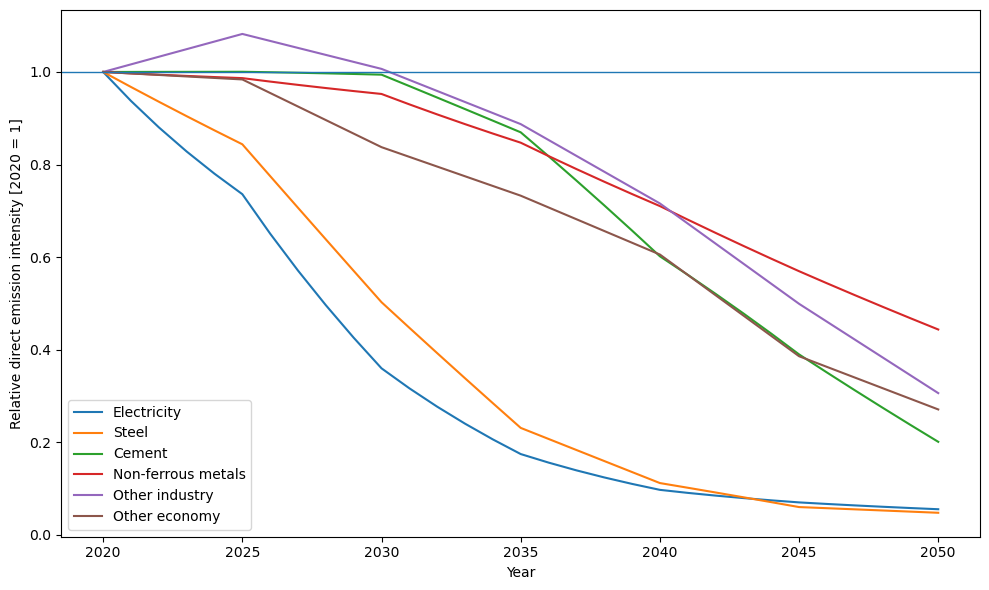

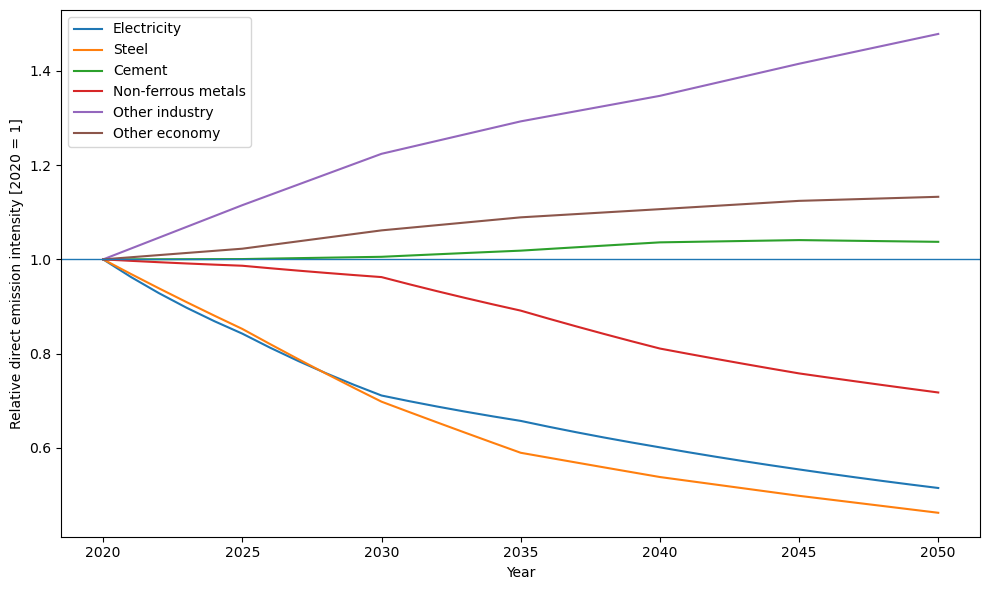

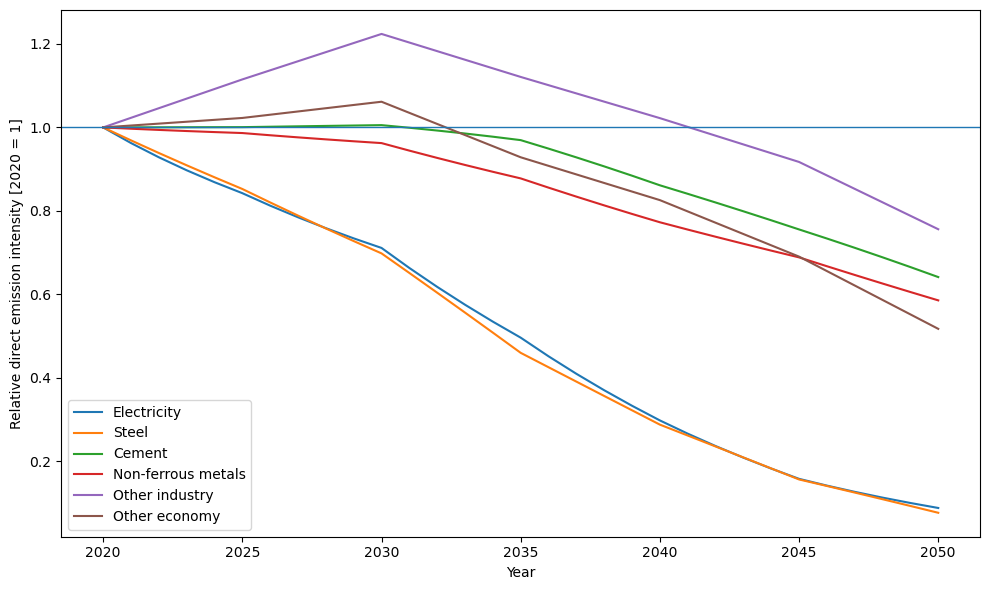

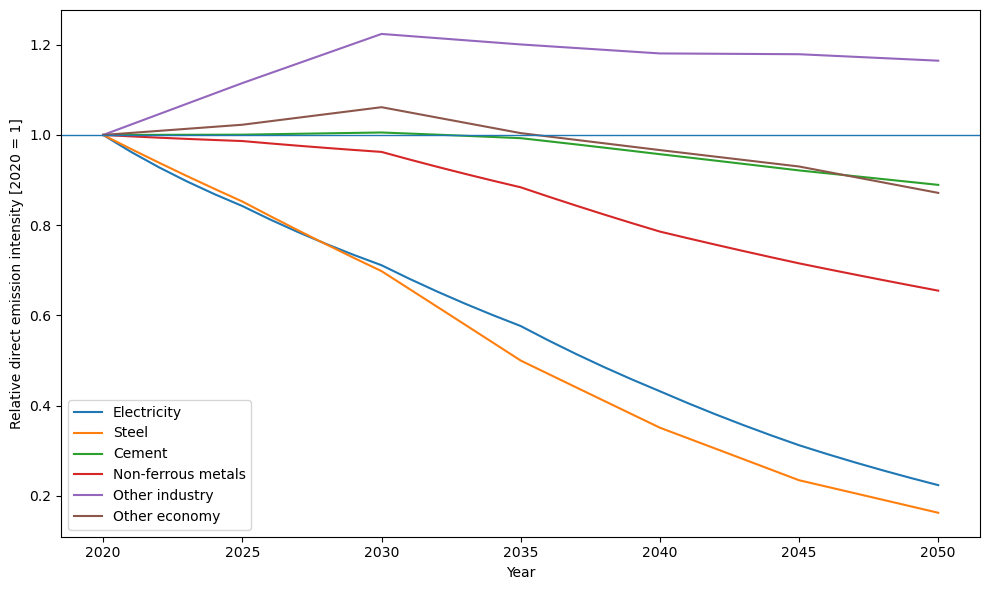

In [18]:
# =========================================================
# OPTIONAL FIGURES:
# GLOBAL RELATIVE IAM EMISSION INTENSITY
#
# Uses ONLY the native GCAM "World" pathway.
# No regional aggregation -> no geographical double counting.
# =========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# ---------------------------------------------------------
# 1. Helper: extract annual GCAM World pathway
# ---------------------------------------------------------

def make_world_annual(variable, value_name):

    df = df_IAM.loc[
        (df_IAM["Model"] == "GCAM 6.0 NGFS")
        & (df_IAM["Scenario"].isin(scenario_analysis))
        & (df_IAM["Region"] == "World")
        & (df_IAM["Variable"] == variable)
    ].copy()

    if df.empty:
        raise ValueError(
            f"World IAM variable not found: {variable}"
        )

    year_cols = [
        c for c in df.columns
        if str(c).isdigit()
    ]

    df[year_cols] = (
        df[year_cols]
        .replace(",", ".", regex=True)
        .apply(pd.to_numeric, errors="coerce")
    )

    df = df.rename(
        columns={
            c: int(c)
            for c in year_cols
        }
    )

    source_years = sorted(
        int(c) for c in year_cols
    )

    annual = (
        df
        .set_index(["Scenario"])[source_years]
        .reindex(columns=range(2020, 2051))
        .interpolate(axis=1, method="linear")
        .reset_index()
    )

    annual = annual.melt(
        id_vars=["Scenario"],
        value_vars=list(range(2020, 2051)),
        var_name="year",
        value_name=value_name
    )

    annual["year"] = annual["year"].astype(int)

    return annual


# ---------------------------------------------------------
# 2. Variables required for the World diagnostic
# ---------------------------------------------------------

world_variables = {

    # Economy-wide
    "kyoto":
        "Emissions|Kyoto Gases",

    "afolu":
        "Emissions|Kyoto Gases|AFOLU",

    "ccs_total":
        "Carbon Sequestration|CCS",

    # Electricity
    "electricity_net":
        "Emissions|Kyoto Gases|Electricity",

    "electricity_ccs_bio":
        "Carbon Sequestration|CCS|Biomass|Energy|Supply|Electricity",

    "electricity_ccs_fossil":
        "Carbon Sequestration|CCS|Fossil|Energy|Supply|Electricity",

    "electricity_output":
        "Secondary Energy|Electricity",

    # Industry
    "industry_net":
        "Emissions|Kyoto Gases|Industry",

    "industry_ccs_bio":
        "Carbon Sequestration|CCS|Biomass|Energy|Demand|Industry",

    "industry_ccs_fossil":
        "Carbon Sequestration|CCS|Fossil|Energy|Demand|Industry",

    "industry_ccs_process":
        "Carbon Sequestration|CCS|Industrial Processes",

    "other_industry_emissions":
        "Emissions|Kyoto Gases|Other Industry",

    # Steel
    "steel_emissions":
        "Emissions|Kyoto Gases|Steel",

    "steel_output":
        "Production|Steel",

    # Cement
    "cement_emissions":
        "Emissions|Kyoto Gases|Cement",

    "cement_output":
        "Production|Cement",

    # Non-ferrous metals
    "nonferrous_emissions":
        "Emissions|CO2|Energy|Demand|Industry|Non-ferrous metals",

    "nonferrous_output":
        "Production|Non-ferrous metals",
}


# ---------------------------------------------------------
# 3. Merge all World pathways
# ---------------------------------------------------------

world_IAM = None

for column, variable in world_variables.items():

    temp = make_world_annual(
        variable,
        column
    )

    if world_IAM is None:

        world_IAM = temp

    else:

        world_IAM = world_IAM.merge(
            temp,
            on=["Scenario", "year"],
            how="outer",
            validate="one_to_one"
        )


# ---------------------------------------------------------
# 4. Reconstruct gross emissions
# ---------------------------------------------------------

world_IAM["gross_nonafolu"] = (
    world_IAM["kyoto"]
    - world_IAM["afolu"]
    + world_IAM["ccs_total"]
)


world_IAM["gross_electricity"] = (
    world_IAM["electricity_net"]
    + world_IAM["electricity_ccs_bio"]
    + world_IAM["electricity_ccs_fossil"]
).clip(lower=0)


world_IAM["gross_industry"] = (
    world_IAM["industry_net"]
    + world_IAM["industry_ccs_bio"]
    + world_IAM["industry_ccs_fossil"]
    + world_IAM["industry_ccs_process"]
).clip(lower=0)


world_IAM["other_economy_emissions"] = (
    world_IAM["gross_nonafolu"]
    - world_IAM["gross_electricity"]
    - world_IAM["gross_industry"]
).clip(lower=0)


world_IAM["other_industry_emissions_positive"] = (
    world_IAM["other_industry_emissions"]
    .clip(lower=0)
)


# ---------------------------------------------------------
# 5. Physical emission intensities
# ---------------------------------------------------------

world_IAM["electricity_intensity"] = (
    world_IAM["gross_electricity"]
    / world_IAM["electricity_output"]
)

world_IAM["steel_intensity"] = (
    world_IAM["steel_emissions"]
    / world_IAM["steel_output"]
)

world_IAM["cement_intensity"] = (
    world_IAM["cement_emissions"]
    / world_IAM["cement_output"]
)

world_IAM["nonferrous_intensity"] = (
    world_IAM["nonferrous_emissions"]
    / world_IAM["nonferrous_output"]
)


# ---------------------------------------------------------
# 6. 2020 baseline for each scenario
# ---------------------------------------------------------

baseline_columns = [
    "electricity_intensity",
    "steel_intensity",
    "cement_intensity",
    "nonferrous_intensity",
    "other_industry_emissions_positive",
    "other_economy_emissions",
]

world_2020 = (
    world_IAM.loc[
        world_IAM["year"] == 2020,
        ["Scenario"] + baseline_columns
    ]
    .rename(
        columns={
            col: f"{col}_2020"
            for col in baseline_columns
        }
    )
)


world_IAM = world_IAM.merge(
    world_2020,
    on="Scenario",
    how="left",
    validate="many_to_one"
)


# ---------------------------------------------------------
# 7. Relative emission-intensity factors
#    2020 = 1
# ---------------------------------------------------------

world_IAM["electricity_factor"] = (
    world_IAM["electricity_intensity"]
    / world_IAM["electricity_intensity_2020"]
)

world_IAM["steel_factor"] = (
    world_IAM["steel_intensity"]
    / world_IAM["steel_intensity_2020"]
)

world_IAM["cement_factor"] = (
    world_IAM["cement_intensity"]
    / world_IAM["cement_intensity_2020"]
)

world_IAM["nonferrous_factor"] = (
    world_IAM["nonferrous_intensity"]
    / world_IAM["nonferrous_intensity_2020"]
)


# Constant-production assumption
world_IAM["other_industry_factor"] = (
    world_IAM["other_industry_emissions_positive"]
    / world_IAM["other_industry_emissions_positive_2020"]
)

world_IAM["other_economy_factor"] = (
    world_IAM["other_economy_emissions"]
    / world_IAM["other_economy_emissions_2020"]
)


# ---------------------------------------------------------
# 8. Plot four separate figures
# ---------------------------------------------------------

factor_columns = [
    "electricity_factor",
    "steel_factor",
    "cement_factor",
    "nonferrous_factor",
    "other_industry_factor",
    "other_economy_factor",
]

labels = {
    "electricity_factor":
        "Electricity",

    "steel_factor":
        "Steel",

    "cement_factor":
        "Cement",

    "nonferrous_factor":
        "Non-ferrous metals",

    "other_industry_factor":
        "Other industry",

    "other_economy_factor":
        "Other economy",
}


for scenario in scenario_analysis:

    plot_data = (
        world_IAM.loc[
            world_IAM["Scenario"] == scenario
        ]
        .sort_values("year")
    )

    plt.figure(figsize=(10, 6))

    for col in factor_columns:

        plt.plot(
            plot_data["year"],
            plot_data[col],
            label=labels[col]
        )

    plt.axhline(
        1,
        linewidth=1
    )

    plt.xlabel("Year")

    plt.ylabel(
        "Relative direct emission intensity "
        "[2020 = 1]"
    )



    plt.legend()

    plt.tight_layout()

    plt.show()

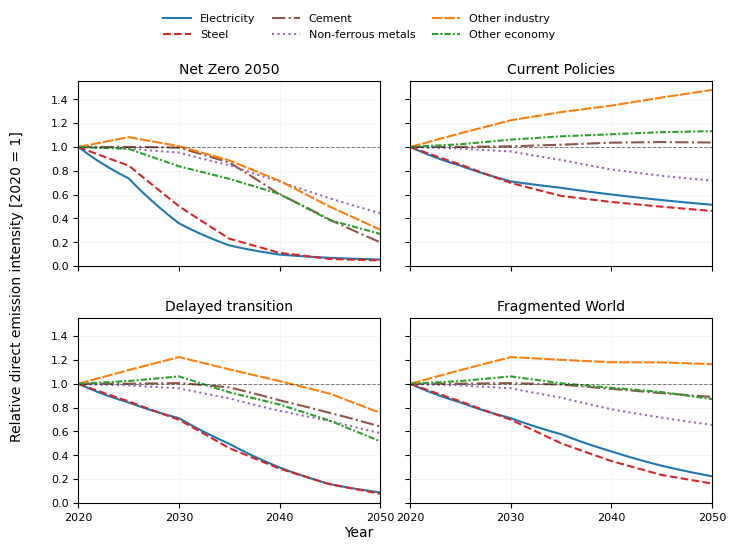

In [19]:
# ============================================================
# 8. PLOT GLOBAL IAM FACTORS — 2 x 2
# ============================================================

import numpy as np
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# SETTINGS
# ------------------------------------------------------------

factor_columns = [
    "electricity_factor",
    "steel_factor",
    "cement_factor",
    "nonferrous_factor",
    "other_industry_factor",
    "other_economy_factor",
]

labels = {
    "electricity_factor": "Electricity",
    "steel_factor": "Steel",
    "cement_factor": "Cement",
    "nonferrous_factor": "Non-ferrous metals",
    "other_industry_factor": "Other industry",
    "other_economy_factor": "Other economy",
}

# Consistent colours across all four panels
colors = {
    "electricity_factor": "#1f77b4",
    "steel_factor": "#d62728",
    "cement_factor": "#8c564b",
    "nonferrous_factor": "#9467bd",
    "other_industry_factor": "#ff7f0e",
    "other_economy_factor": "#2ca02c",
}

# Line styles also make the figure readable in greyscale
linestyles = {
    "electricity_factor": "-",
    "steel_factor": "--",
    "cement_factor": "-.",
    "nonferrous_factor": ":",
    "other_industry_factor": (0, (5, 1)),
    "other_economy_factor": (0, (3, 1, 1, 1)),
}

TITLE_SIZE = 10
LABEL_SIZE = 10
TICK_SIZE = 8
LEGEND_SIZE = 8


# ------------------------------------------------------------
# DETERMINE COMMON Y-AXIS
# ------------------------------------------------------------

plot_subset = world_IAM.loc[
    world_IAM["Scenario"].isin(scenario_analysis),
    factor_columns
]

global_max = (
    plot_subset
    .replace([np.inf, -np.inf], np.nan)
    .max()
    .max()
)

y_max = max(
    1.10,
    global_max * 1.05
)


# ------------------------------------------------------------
# CREATE 2 x 2 FIGURE
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(7.2, 5.7),
    sharex=True,
    sharey=True
)

axes = axes.flatten()


for ax, scenario in zip(
    axes,
    scenario_analysis
):

    plot_data = (
        world_IAM.loc[
            world_IAM["Scenario"] == scenario
        ]
        .sort_values("year")
    )


    # --------------------------------------------------------
    # IAM FACTOR LINES
    # --------------------------------------------------------

    for col in factor_columns:

        ax.plot(
            plot_data["year"],
            plot_data[col],
            label=labels[col],
            color=colors[col],
            linestyle=linestyles[col],
            linewidth=1.5
        )


    # 2020 reference level
    ax.axhline(
        1,
        color="black",
        linewidth=0.7,
        linestyle="--",
        alpha=0.5
    )


    # --------------------------------------------------------
    # PANEL FORMATTING
    # --------------------------------------------------------

    ax.set_title(
        scenario,
        fontsize=TITLE_SIZE,
        pad=5
    )

    ax.set_xlim(
        2020,
        2050
    )

    ax.set_ylim(
        0,
        y_max
    )

    ax.set_xticks(
        [2020, 2030, 2040, 2050]
    )

    ax.tick_params(
        axis="both",
        labelsize=TICK_SIZE
    )

    ax.grid(
        axis="both",
        alpha=0.18,
        linewidth=0.5
    )

    ax.set_axisbelow(True)


# ------------------------------------------------------------
# SHARED AXIS LABELS
# ------------------------------------------------------------

fig.supxlabel(
    "Year",
    fontsize=LABEL_SIZE,
    y=0.055
)

fig.supylabel(
    "Relative direct emission intensity [2020 = 1]",
    fontsize=LABEL_SIZE,
    x=0.015
)


# ------------------------------------------------------------
# SHARED LEGEND
# ------------------------------------------------------------

handles, legend_labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    legend_labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.995),
    ncol=3,
    frameon=False,
    fontsize=LEGEND_SIZE,
    handlelength=2.5,
    columnspacing=1.5
)


# ------------------------------------------------------------
# SPACING
# ------------------------------------------------------------

fig.subplots_adjust(
    left=0.11,
    right=0.99,
    bottom=0.12,
    top=0.86,
    wspace=0.10,
    hspace=0.28
)

plt.savefig(r"C:\Users\menne\Documents\Master\Thesis\Figuren\results\spores\mean\Emission_pathway")
plt.show()

In [20]:
# ============================================================
# FULL EXIOBASE -> IAM MAPPING TABLE FOR APPENDIX
# ============================================================

mapping_appendix = (
    df_S_base[
        [
            "sector",
            "emission_group"
        ]
    ]
    .drop_duplicates()
    .sort_values(
        [
            "emission_group",
            "sector"
        ]
    )
)

mapping_appendix["emission_group"] = (
    mapping_appendix["emission_group"]
    .replace({
        "electricity": "Electricity",
        "steel": "Steel",
        "cement": "Cement",
        "nonferrous": "Non-ferrous metals",
        "other_industry": "Other industry",
        "other_economy": "Other economy",
    })
)

latex_table = mapping_appendix.to_latex(
    index=False,
    longtable=True,
    escape=True,
    columns=[
        "sector",
        "emission_group"
    ],
    header=[
        "EXIOBASE product",
        "IAM group"
    ],
    caption=(
        "Complete mapping of EXIOBASE products "
        "to IAM emission pathways."
    ),
    label="tab:full_exiobase_iam_mapping"
)

print(latex_table)

\begin{longtable}{ll}
\caption{Complete mapping of EXIOBASE products to IAM emission pathways.} \label{tab:full_exiobase_iam_mapping} \\
\toprule
EXIOBASE product & IAM group \\
\midrule
\endfirsthead
\caption[]{Complete mapping of EXIOBASE products to IAM emission pathways.} \\
\toprule
EXIOBASE product & IAM group \\
\midrule
\endhead
\midrule
\multicolumn{2}{r}{Continued on next page} \\
\midrule
\endfoot
\bottomrule
\endlastfoot
Cement, lime and plaster & Cement \\
Electricity by Geothermal & Electricity \\
Electricity by biomass and waste & Electricity \\
Electricity by coal & Electricity \\
Electricity by gas & Electricity \\
Electricity by hydro & Electricity \\
Electricity by nuclear & Electricity \\
Electricity by petroleum and other oil derivatives & Electricity \\
Electricity by solar photovoltaic & Electricity \\
Electricity by solar thermal & Electricity \\
Electricity by tide, wave, ocean & Electricity \\
Electricity by wind & Electricity \\
Electricity nec & Electricity 

Rows loaded: 1,215,200

Excluded R5 regions:
 - Asia (R5)
 - Latin America (R5)
 - Middle East & Africa (R5)
 - Reforming Economies (R5)

Number of non-R5 regions: 17

Figure order:
01. Australia_NZ
02. Brazil
03. Canada
04. China
05. EU-12
06. EU-15
07. Europe_Non_EU
08. European Free Trade Association
09. India
10. Indonesia
11. Japan
12. Mexico
13. Russia
14. South Africa
15. South Korea
16. Taiwan
17. USA

IAM regions containing different final country-level factors:
 - EU-15

The plotted regional pathway uses the median of the country-level factors.

Creating figure 01: Australia_NZ
Saved: C:\Users\menne\Documents\Master\Thesis\results\S_pathway\01_Emission_pathway_Australia_NZ.png


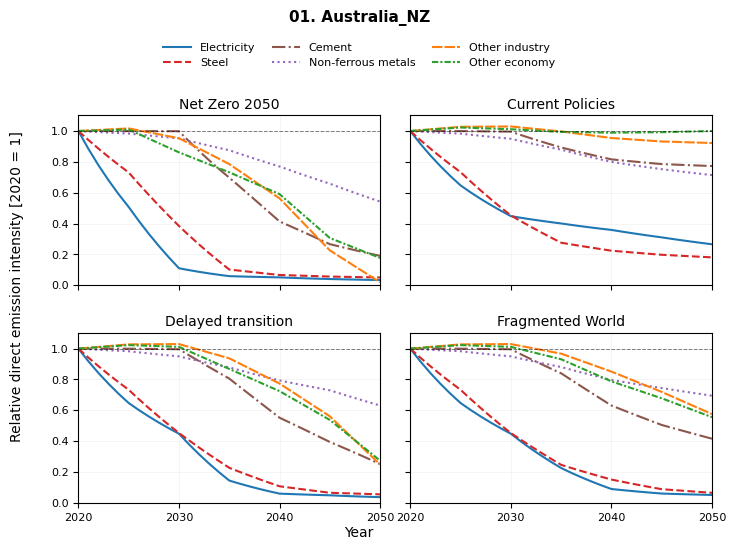


Creating figure 02: Brazil
Saved: C:\Users\menne\Documents\Master\Thesis\results\S_pathway\02_Emission_pathway_Brazil.png


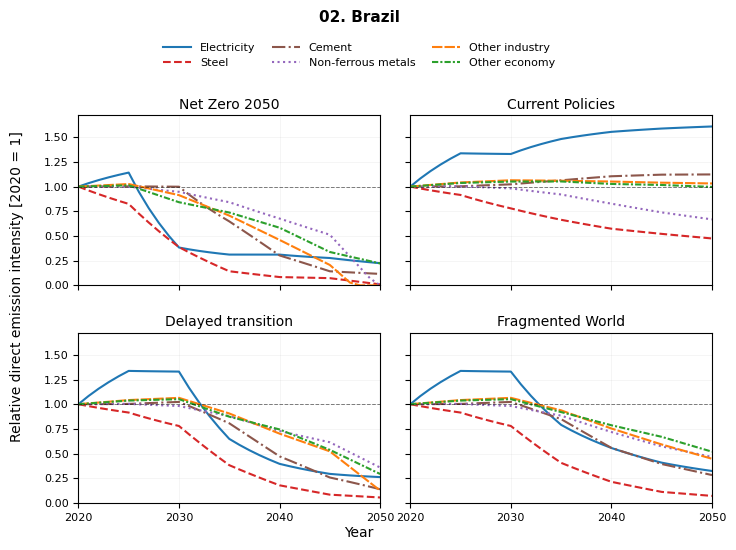


Creating figure 03: Canada
Saved: C:\Users\menne\Documents\Master\Thesis\results\S_pathway\03_Emission_pathway_Canada.png


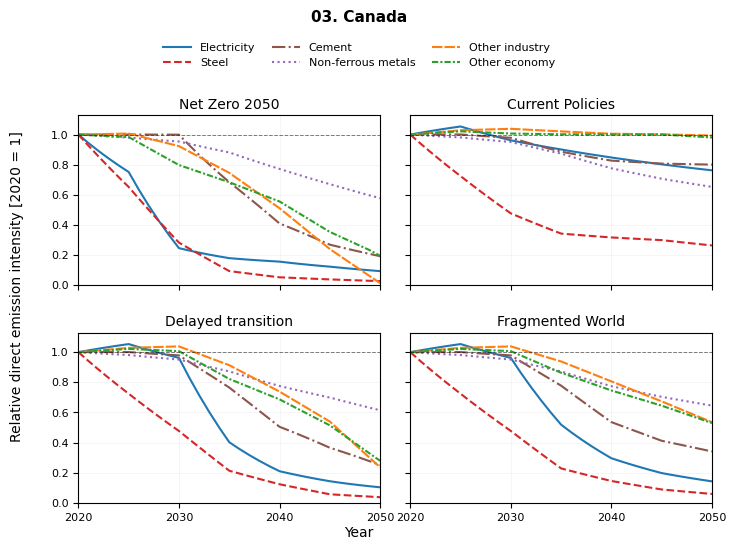


Creating figure 04: China
Saved: C:\Users\menne\Documents\Master\Thesis\results\S_pathway\04_Emission_pathway_China.png


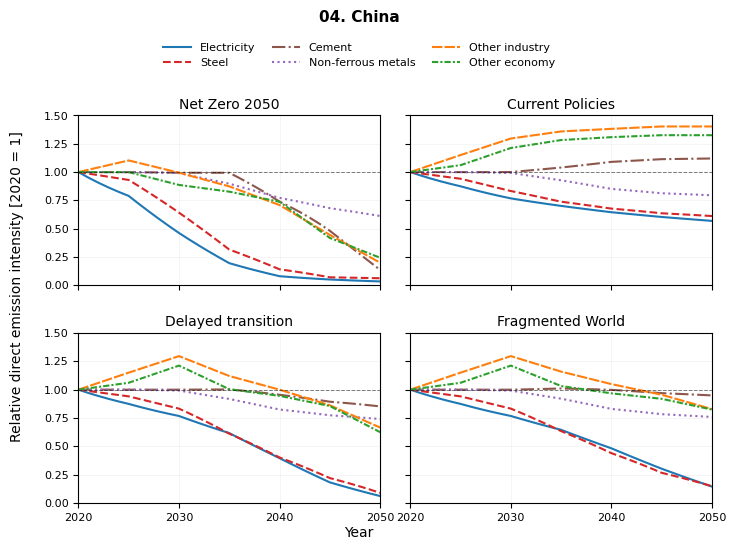


Creating figure 05: EU-12
Saved: C:\Users\menne\Documents\Master\Thesis\results\S_pathway\05_Emission_pathway_EU-12.png


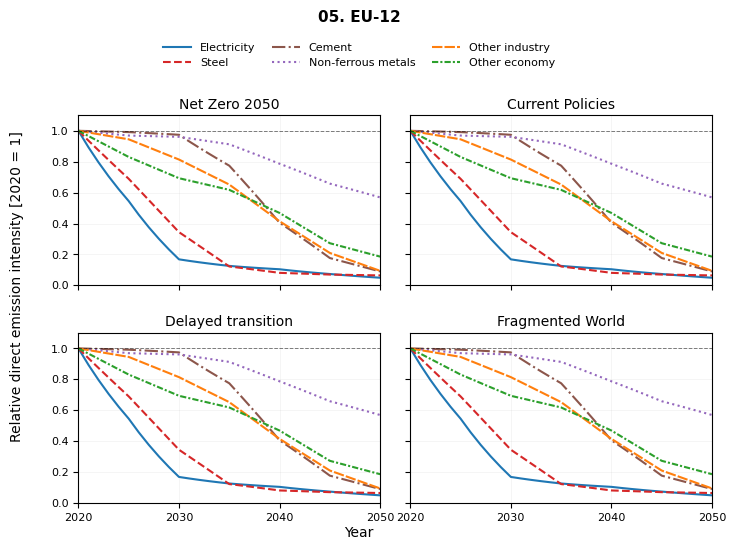


Creating figure 06: EU-15
Saved: C:\Users\menne\Documents\Master\Thesis\results\S_pathway\06_Emission_pathway_EU-15.png


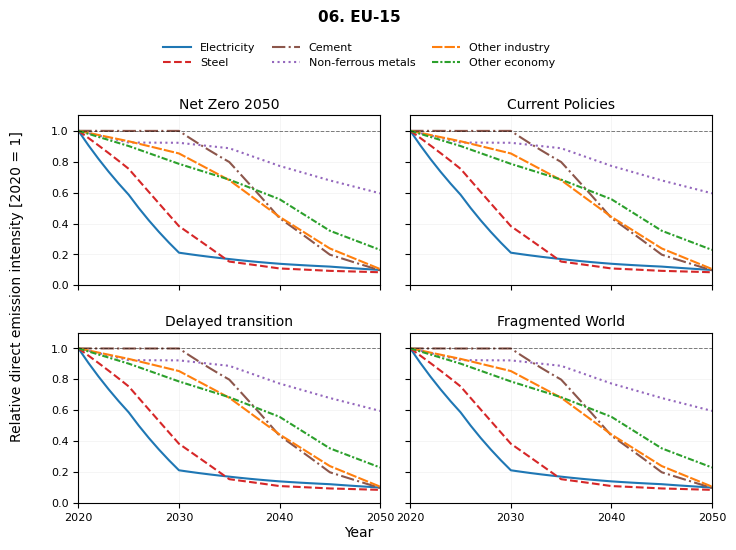


Creating figure 07: Europe_Non_EU
Saved: C:\Users\menne\Documents\Master\Thesis\results\S_pathway\07_Emission_pathway_Europe_Non_EU.png


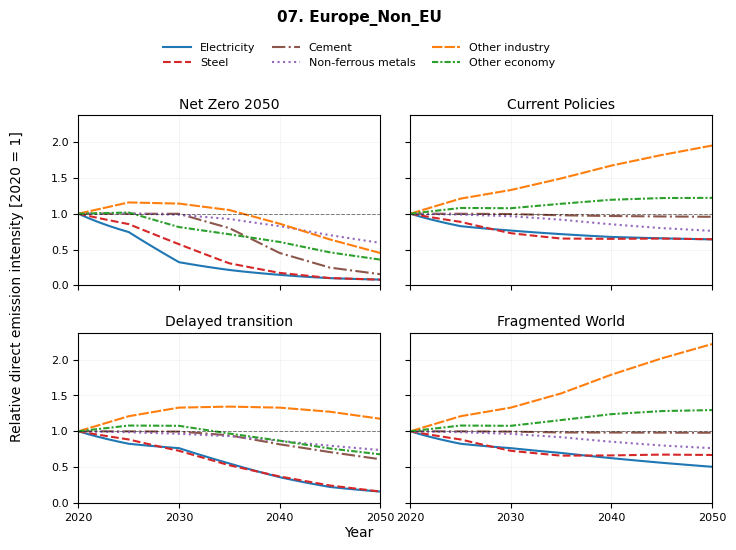


Creating figure 08: European Free Trade Association
Saved: C:\Users\menne\Documents\Master\Thesis\results\S_pathway\08_Emission_pathway_European_Free_Trade_Association.png


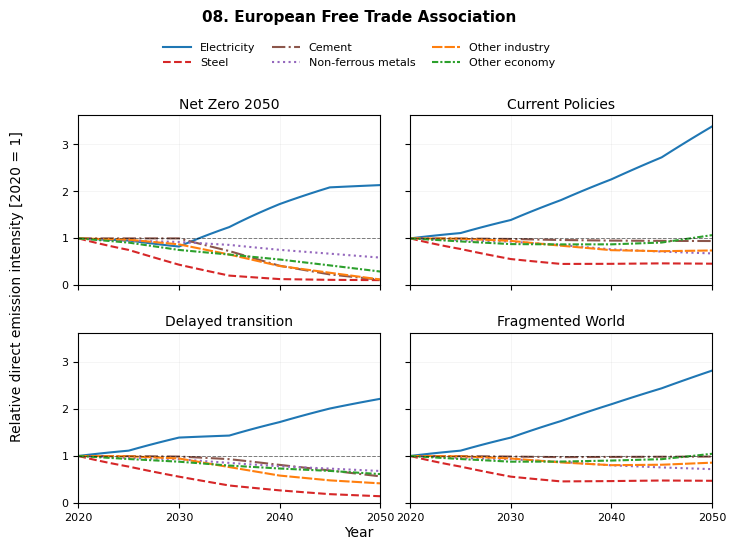


Creating figure 09: India
Saved: C:\Users\menne\Documents\Master\Thesis\results\S_pathway\09_Emission_pathway_India.png


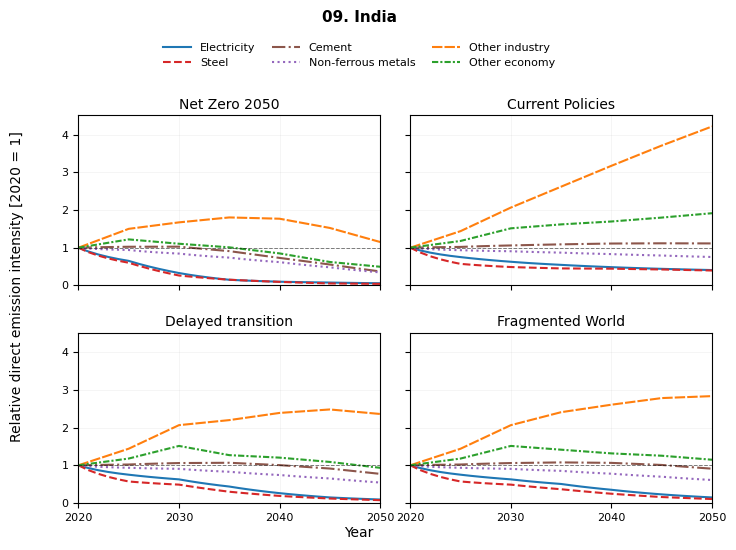


Creating figure 10: Indonesia
Saved: C:\Users\menne\Documents\Master\Thesis\results\S_pathway\10_Emission_pathway_Indonesia.png


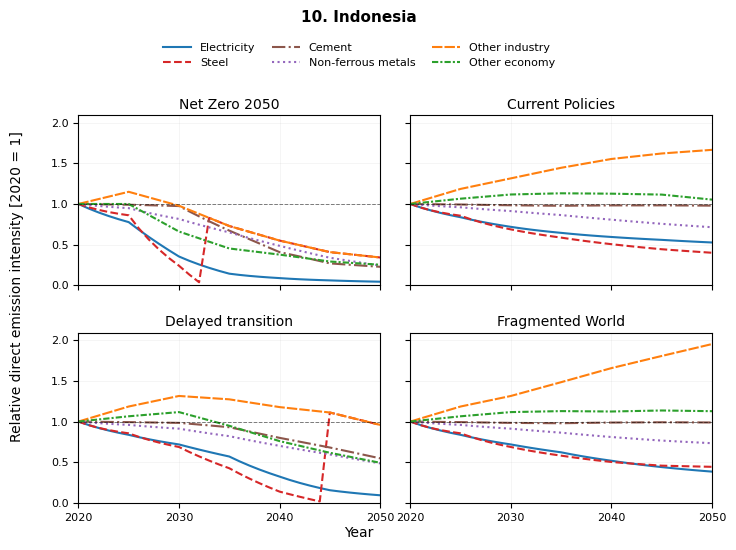


Creating figure 11: Japan
Saved: C:\Users\menne\Documents\Master\Thesis\results\S_pathway\11_Emission_pathway_Japan.png


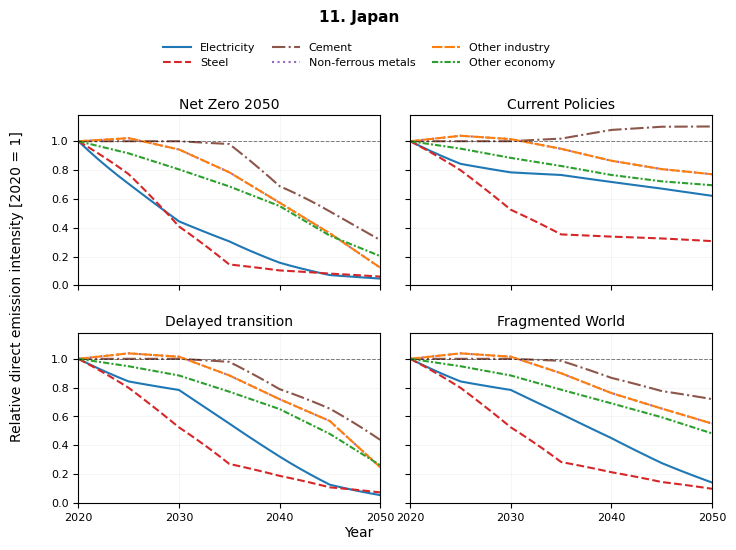


Creating figure 12: Mexico
Saved: C:\Users\menne\Documents\Master\Thesis\results\S_pathway\12_Emission_pathway_Mexico.png


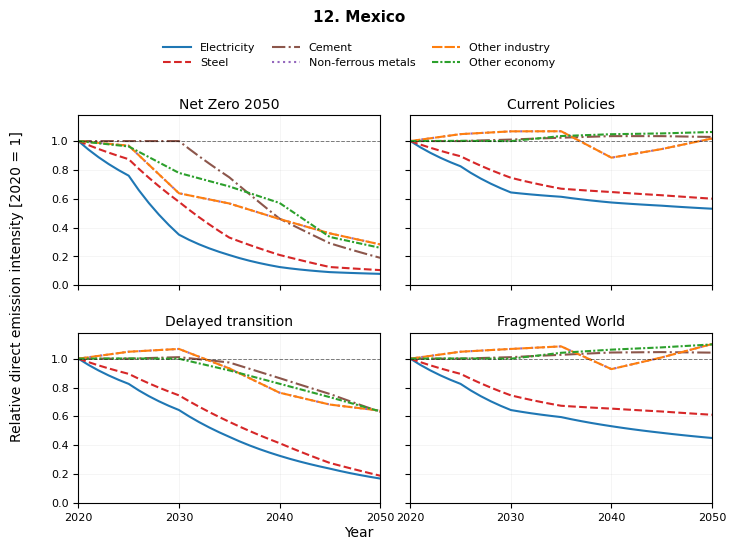


Creating figure 13: Russia
Saved: C:\Users\menne\Documents\Master\Thesis\results\S_pathway\13_Emission_pathway_Russia.png


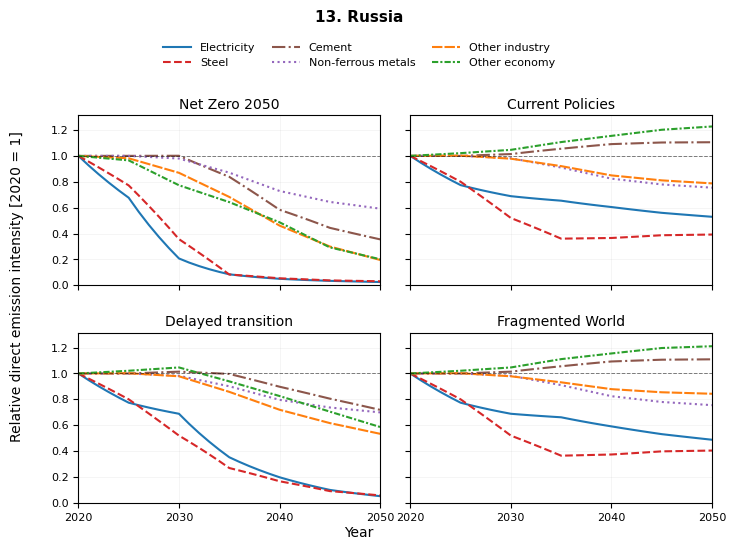


Creating figure 14: South Africa
Saved: C:\Users\menne\Documents\Master\Thesis\results\S_pathway\14_Emission_pathway_South_Africa.png


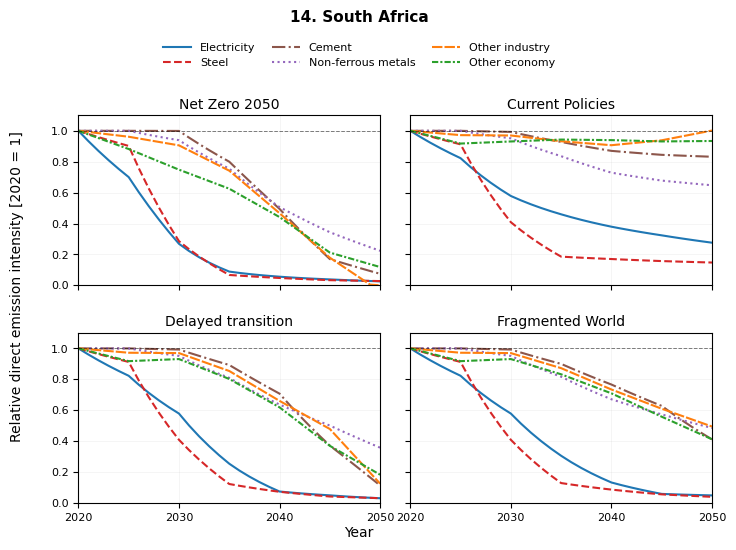


Creating figure 15: South Korea
Saved: C:\Users\menne\Documents\Master\Thesis\results\S_pathway\15_Emission_pathway_South_Korea.png


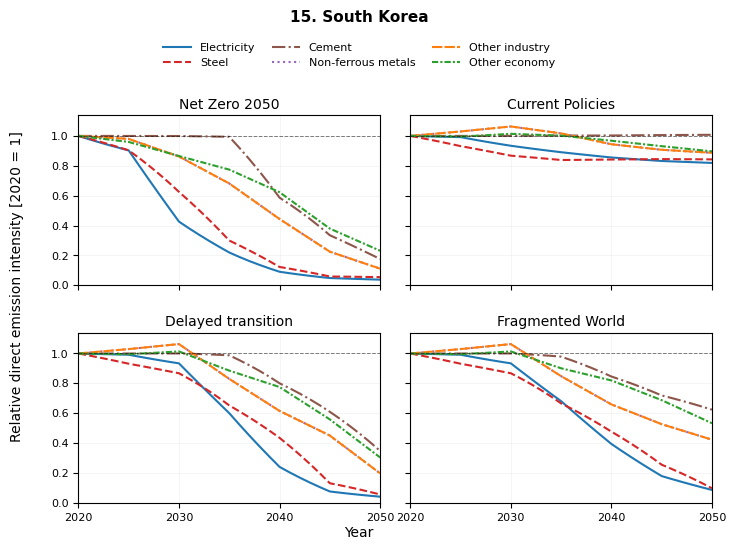


Creating figure 16: Taiwan
Saved: C:\Users\menne\Documents\Master\Thesis\results\S_pathway\16_Emission_pathway_Taiwan.png


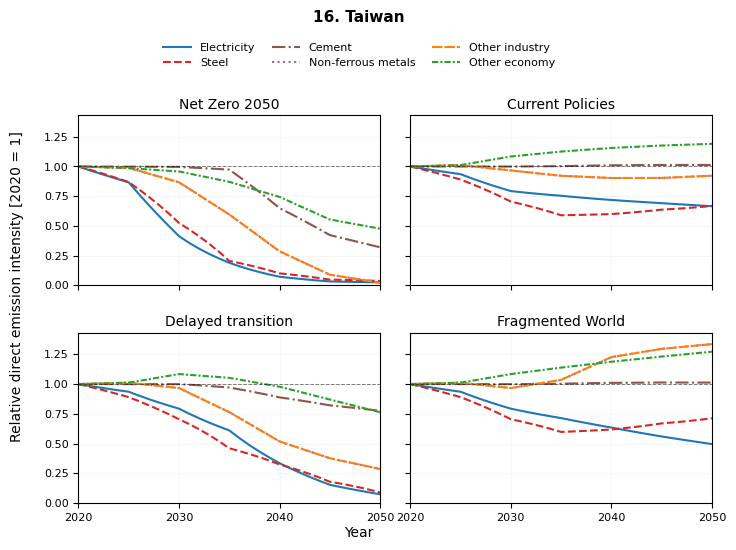


Creating figure 17: USA
Saved: C:\Users\menne\Documents\Master\Thesis\results\S_pathway\17_Emission_pathway_USA.png


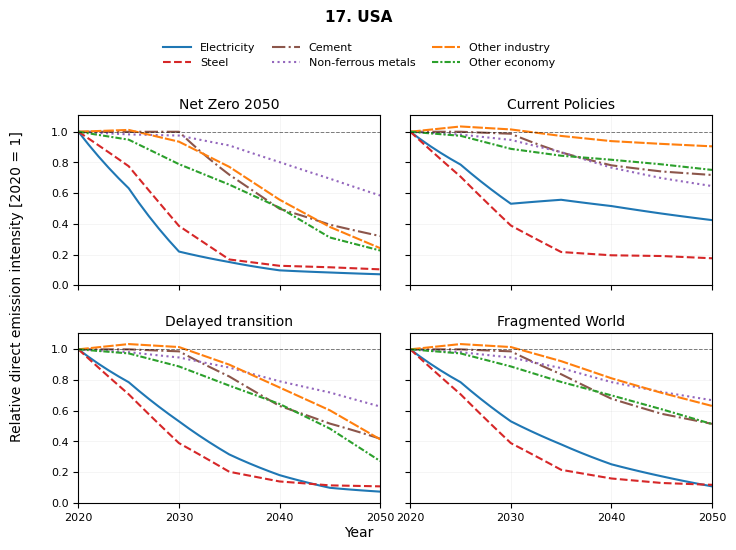


FINISHED
Created 17 figures.

Saved to:
C:\Users\menne\Documents\Master\Thesis\results\S_pathway


In [24]:
# ============================================================
# REGIONAL EXIOBASE EMISSION-INTENSITY PATHWAYS
#
# Source:
# EXIOBASE_S_pathway.csv
#
# Uses the FINAL IAM_factor from the EXIOBASE pathway file,
# including the EU27 Net Zero override already applied there.
#
# Creates:
# - 17 regional figures
# - R5 aggregate regions are excluded
# - numbered 01 to 17
# - PNG output
# ============================================================


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import re


# ============================================================
# 1. FILE PATHS
# ============================================================

csv_file = Path(
    r"C:\Users\menne\Documents\Master\Thesis\Data\MRIO\Exiobase\Emissions\EXIOBASE_S_pathway.csv"
)

output_dir = Path(
    r"C:\Users\menne\Documents\Master\Thesis\results\S_pathway"
)

output_dir.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 2. SCENARIOS
# ============================================================

scenario_analysis = [
    "Net Zero 2050",
    "Current Policies",
    "Delayed transition",
    "Fragmented World",
]


# ============================================================
# 3. EMISSION GROUPS
# ============================================================

emission_groups = [
    "electricity",
    "steel",
    "cement",
    "nonferrous",
    "other_industry",
    "other_economy",
]


# ============================================================
# 4. DISPLAY LABELS
# ============================================================

labels = {
    "electricity": "Electricity",
    "steel": "Steel",
    "cement": "Cement",
    "nonferrous": "Non-ferrous metals",
    "other_industry": "Other industry",
    "other_economy": "Other economy",
}


# ============================================================
# 5. COLOURS
# ============================================================

colors = {
    "electricity": "#1f77b4",
    "steel": "#d62728",
    "cement": "#8c564b",
    "nonferrous": "#9467bd",
    "other_industry": "#ff7f0e",
    "other_economy": "#2ca02c",
}


# ============================================================
# 6. LINE STYLES
# ============================================================

linestyles = {
    "electricity": "-",
    "steel": "--",
    "cement": "-.",
    "nonferrous": ":",
    "other_industry": (0, (5, 1)),
    "other_economy": (0, (3, 1, 1, 1)),
}


# ============================================================
# 7. FIGURE SETTINGS
# ============================================================

TITLE_SIZE = 10
REGION_TITLE_SIZE = 11
LABEL_SIZE = 10
TICK_SIZE = 8
LEGEND_SIZE = 8


# ============================================================
# 8. HELPER FUNCTIONS
# ============================================================

def clean_region_name(region):
    """
    Example:

    GCAM 6.0 NGFS|EU-15

    becomes:

    EU-15
    """

    region = str(region)

    if "|" in region:
        return region.split("|")[-1].strip()

    return region.strip()


def safe_filename(text):
    """
    Convert region name into a safe filename.
    """

    text = clean_region_name(text)

    text = re.sub(
        r"[^A-Za-z0-9_-]+",
        "_",
        text
    )

    return text.strip("_")


# ============================================================
# 9. READ CSV
# ============================================================

# Only load the columns required for plotting.
# This keeps memory usage substantially lower.

usecols = [
    "Region",
    "emission_group",
    "IAM_region",
    "Scenario",
    "year",
    "IAM_factor",
]


df = pd.read_csv(
    csv_file,
    sep=";",
    usecols=usecols,
    low_memory=False,
)


print(
    "Rows loaded:",
    f"{len(df):,}"
)


# ============================================================
# 10. CLEAN DATA TYPES
# ============================================================

df["year"] = pd.to_numeric(
    df["year"],
    errors="coerce"
)

df["IAM_factor"] = pd.to_numeric(
    df["IAM_factor"],
    errors="coerce"
)


# ============================================================
# 11. FILTER TO REQUIRED DATA
# ============================================================

df = df.loc[
    df["Scenario"].isin(
        scenario_analysis
    )
    &
    df["emission_group"].isin(
        emission_groups
    )
    &
    df["year"].between(
        2020,
        2050
    )
].copy()


# ============================================================
# 12. CLEAN IAM REGION NAMES
# ============================================================

df["region_name"] = (
    df["IAM_region"]
    .map(clean_region_name)
)


# ============================================================
# 13. REMOVE R5 REGIONS
# ============================================================

r5_mask = (
    df["region_name"]
    .str.contains(
        r"\(R5\)",
        regex=True,
        na=False
    )
)


excluded_R5 = sorted(
    df.loc[
        r5_mask,
        "region_name"
    ]
    .dropna()
    .unique()
    .tolist()
)


df = (
    df.loc[
        ~r5_mask
    ]
    .copy()
)


print(
    "\nExcluded R5 regions:"
)

for region in excluded_R5:
    print(
        " -",
        region
    )


# ============================================================
# 14. REMOVE DUPLICATE SECTOR OBSERVATIONS
# ============================================================

# IAM_factor is applied to many EXIOBASE sectors belonging
# to the same emission group.
#
# We first reduce the dataframe to one factor per:
#
# EXIOBASE country
# × IAM region
# × scenario
# × year
# × emission group
#
# This prevents countries from being weighted multiple times
# simply because many EXIOBASE sectors belong to the same
# emission group.

country_factors = (
    df[
        [
            "Region",
            "IAM_region",
            "region_name",
            "Scenario",
            "year",
            "emission_group",
            "IAM_factor",
        ]
    ]
    .drop_duplicates()
)


# ============================================================
# 15. CREATE REPRESENTATIVE IAM-REGION PATHWAYS
# ============================================================

# In most IAM regions all EXIOBASE countries have exactly
# the same IAM_factor.
#
# EU-15 is different because the final CSV contains the EU27
# Net Zero override, while GB remains scenario dependent.
#
# The regional figure therefore reports the median factor
# across the EXIOBASE countries mapped to each IAM region.

regional_factors = (
    country_factors
    .groupby(
        [
            "IAM_region",
            "region_name",
            "Scenario",
            "year",
            "emission_group",
        ],
        as_index=False,
    )["IAM_factor"]
    .median()
)


# ============================================================
# 16. DETERMINE 17 REGION ORDER
# ============================================================

region_order = sorted(
    regional_factors[
        "region_name"
    ]
    .dropna()
    .unique(),
    key=str.lower,
)


print(
    "\nNumber of non-R5 regions:",
    len(region_order)
)


if len(region_order) != 17:

    raise ValueError(
        "Expected 17 non-R5 IAM regions, "
        f"but found {len(region_order)}."
    )


print(
    "\nFigure order:"
)

for i, region in enumerate(
    region_order,
    start=1
):

    print(
        f"{i:02d}. {region}"
    )


# ============================================================
# 17. REGION LOOKUP
# ============================================================

region_lookup = (
    regional_factors[
        [
            "region_name",
            "IAM_region",
        ]
    ]
    .drop_duplicates()
    .set_index(
        "region_name"
    )["IAM_region"]
    .to_dict()
)


# ============================================================
# 18. VALIDATION:
#     CHECK WHETHER COUNTRIES WITHIN EACH IAM REGION DIFFER
# ============================================================

factor_variation = (
    country_factors
    .groupby(
        [
            "IAM_region",
            "Scenario",
            "year",
            "emission_group",
        ]
    )["IAM_factor"]
    .nunique()
)


regions_with_internal_variation = (
    factor_variation[
        factor_variation > 1
    ]
    .reset_index()[
        "IAM_region"
    ]
    .drop_duplicates()
    .tolist()
)


if regions_with_internal_variation:

    print(
        "\nIAM regions containing different final "
        "country-level factors:"
    )

    for region in regions_with_internal_variation:

        print(
            " -",
            clean_region_name(region)
        )

    print(
        "\nThe plotted regional pathway uses the median "
        "of the country-level factors."
    )


# ============================================================
# 19. FUNCTION TO CREATE ONE REGIONAL FIGURE
# ============================================================

def plot_region(
    region_name,
    figure_number,
):

    IAM_region = region_lookup[
        region_name
    ]


    # --------------------------------------------------------
    # Regional data
    # --------------------------------------------------------

    region_data = (
        regional_factors.loc[
            regional_factors[
                "IAM_region"
            ].eq(
                IAM_region
            )
        ]
        .copy()
    )


    if region_data.empty:

        print(
            f"No data found for {region_name}"
        )

        return None


    # ========================================================
    # DETERMINE COMMON Y-AXIS
    # ========================================================

    region_max = (
        region_data[
            "IAM_factor"
        ]
        .replace(
            [np.inf, -np.inf],
            np.nan
        )
        .max()
    )


    if pd.isna(region_max):
        region_max = 1.0


    y_max = max(
        1.10,
        float(region_max) * 1.07
    )


    # ========================================================
    # CREATE 2 x 2 FIGURE
    # ========================================================

    fig, axes = plt.subplots(
        2,
        2,
        figsize=(7.2, 5.7),
        sharex=True,
        sharey=True,
    )

    axes = axes.flatten()


    # ========================================================
    # SCENARIO PANELS
    # ========================================================

    for ax, scenario in zip(
        axes,
        scenario_analysis
    ):

        scenario_data = (
            region_data.loc[
                region_data[
                    "Scenario"
                ].eq(
                    scenario
                )
            ]
            .copy()
        )


        # ----------------------------------------------------
        # Plot six emission groups
        # ----------------------------------------------------

        for group in emission_groups:

            plot_data = (
                scenario_data.loc[
                    scenario_data[
                        "emission_group"
                    ].eq(
                        group
                    )
                ]
                .sort_values(
                    "year"
                )
            )


            ax.plot(
                plot_data["year"],
                plot_data["IAM_factor"],
                label=labels[group],
                color=colors[group],
                linestyle=linestyles[group],
                linewidth=1.5,
            )


        # ----------------------------------------------------
        # 2020 reference line
        # ----------------------------------------------------

        ax.axhline(
            y=1,
            color="black",
            linewidth=0.7,
            linestyle="--",
            alpha=0.5,
        )


        # ----------------------------------------------------
        # Panel title
        # ----------------------------------------------------

        ax.set_title(
            scenario,
            fontsize=TITLE_SIZE,
            pad=5,
        )


        # ----------------------------------------------------
        # Axis limits
        # ----------------------------------------------------

        ax.set_xlim(
            2020,
            2050
        )

        ax.set_ylim(
            0,
            y_max
        )


        # ----------------------------------------------------
        # X ticks
        # ----------------------------------------------------

        ax.set_xticks(
            [
                2020,
                2030,
                2040,
                2050,
            ]
        )


        # ----------------------------------------------------
        # Formatting
        # ----------------------------------------------------

        ax.tick_params(
            axis="both",
            labelsize=TICK_SIZE,
        )

        ax.grid(
            axis="both",
            alpha=0.18,
            linewidth=0.5,
        )

        ax.set_axisbelow(
            True
        )


    # ========================================================
    # SHARED AXIS LABELS
    # ========================================================

    fig.supxlabel(
        "Year",
        fontsize=LABEL_SIZE,
        y=0.055,
    )


    fig.supylabel(
        "Relative direct emission intensity [2020 = 1]",
        fontsize=LABEL_SIZE,
        x=0.015,
    )


    # ========================================================
    # NUMBERED REGION TITLE
    # ========================================================

    fig.suptitle(
        f"{figure_number:02d}. {region_name}",
        fontsize=REGION_TITLE_SIZE,
        fontweight="bold",
        y=0.985,
    )


    # ========================================================
    # SHARED LEGEND
    # ========================================================

    handles, legend_labels = (
        axes[0]
        .get_legend_handles_labels()
    )


    fig.legend(
        handles,
        legend_labels,
        loc="upper center",
        bbox_to_anchor=(
            0.5,
            0.945
        ),
        ncol=3,
        frameon=False,
        fontsize=LEGEND_SIZE,
        handlelength=2.5,
        columnspacing=1.5,
    )


    # ========================================================
    # SPACING
    # ========================================================

    fig.subplots_adjust(
        left=0.11,
        right=0.99,
        bottom=0.12,
        top=0.80,
        wspace=0.10,
        hspace=0.28,
    )


    # ========================================================
    # EXACT FILE NAME
    # ========================================================

    filename = (
        f"{figure_number:02d}_"
        f"Emission_pathway_"
        f"{safe_filename(region_name)}.png"
    )


    output_file = (
        output_dir
        / filename
    )


    # ========================================================
    # SAVE FIGURE
    # ========================================================

    fig.savefig(
        output_file,
        dpi=300,
        bbox_inches="tight",
    )


    print(
        "Saved:",
        output_file
    )


    return fig


# ============================================================
# 20. CREATE ALL 17 FIGURES
# ============================================================

for figure_number, region_name in enumerate(
    region_order,
    start=1,
):

    print(
        f"\nCreating figure "
        f"{figure_number:02d}: "
        f"{region_name}"
    )


    fig = plot_region(
        region_name=region_name,
        figure_number=figure_number,
    )


    if fig is not None:

        plt.show()

        plt.close(
            fig
        )


# ============================================================
# 21. FINAL SUMMARY
# ============================================================

print(
    "\n========================================"
)

print(
    "FINISHED"
)

print(
    "========================================"
)

print(
    f"Created {len(region_order)} figures."
)

print(
    "\nSaved to:"
)

print(
    output_dir
)

Number of electricity products found: 14

Electricity products found:
 - Distribution and trade services of electricity
 - Electricity by Geothermal
 - Electricity by biomass and waste
 - Electricity by coal
 - Electricity by gas
 - Electricity by hydro
 - Electricity by nuclear
 - Electricity by petroleum and other oil derivatives
 - Electricity by solar photovoltaic
 - Electricity by solar thermal
 - Electricity by tide, wave, ocean
 - Electricity by wind
 - Electricity nec
 - Transmission services of electricity

2020 DIRECT ELECTRICITY EMISSION INTENSITY

    country  electricity_output_MEUR  electricity_intensity_kgCO2eq_per_MEUR
Switzerland             10599.949806                            3.174373e+04
     Norway              4642.422866                            4.150392e+04
     France             67757.174274                            3.340482e+05
    Germany             81916.968425                            2.040806e+06
Netherlands             10250.264433             

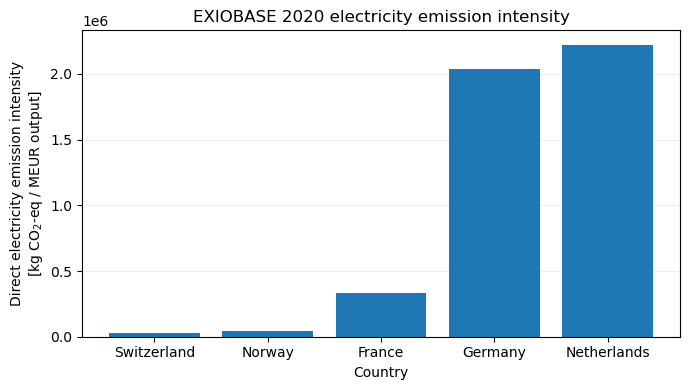

In [23]:
# ============================================================
# EXIOBASE 2020 DIRECT ELECTRICITY EMISSION INTENSITY
#
# Compare:
# - Norway
# - Switzerland
# - Netherlands
# - Germany
# - France
#
# Includes:
# CO2 + CO2_bio + CH4 + N2O + SF6 + HFC + PFC
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# 1. COUNTRIES TO COMPARE
# ============================================================

countries = {
    "NO": "Norway",
    "CH": "Switzerland",
    "NL": "Netherlands",
    "DE": "Germany",
    "FR": "France",
}


# ============================================================
# 2. DIRECT GHG EMISSIONS
# ============================================================

F = exio.air_emissions.F.copy()

labels = pd.Series(
    F.index.astype(str),
    index=F.index
)


# ------------------------------------------------------------
# Kyoto greenhouse gases
# Biogenic CO2 included
# ------------------------------------------------------------

co2_rows = (
    labels.str.startswith("CO2 -")
    | labels.str.startswith("CO2_bio -")
)

ch4_rows = labels.str.startswith("CH4 -")
n2o_rows = labels.str.startswith("N2O -")
sf6_rows = labels.eq("SF6 - air")
hfc_rows = labels.eq("HFC - air")
pfc_rows = labels.eq("PFC - air")


# ------------------------------------------------------------
# GWP100 factors
# ------------------------------------------------------------

GWP_CH4 = 28
GWP_N2O = 265
GWP_SF6 = 23500


# ------------------------------------------------------------
# Absolute direct GHG emissions
# ------------------------------------------------------------

direct_GHG = (
    F.loc[co2_rows].sum(axis=0)
    + GWP_CH4 * F.loc[ch4_rows].sum(axis=0)
    + GWP_N2O * F.loc[n2o_rows].sum(axis=0)
    + GWP_SF6 * F.loc[sf6_rows].sum(axis=0)
    + F.loc[hfc_rows].sum(axis=0)
    + F.loc[pfc_rows].sum(axis=0)
)


# ============================================================
# 3. ECONOMIC OUTPUT
# ============================================================

x = exio.x.iloc[:, 0].copy()


# Align indices just to be safe
direct_GHG = direct_GHG.reindex(x.index)


# ============================================================
# 4. DIRECT EMISSION INTENSITY
# ============================================================

S_direct = direct_GHG / x

S_direct = S_direct.replace(
    [np.inf, -np.inf],
    np.nan
)


# ============================================================
# 5. IDENTIFY ELECTRICITY PRODUCTS
# ============================================================

# EXIOBASE x normally has MultiIndex:
# region × sector

regions = x.index.get_level_values(0)
sectors = x.index.get_level_values(1).astype(str)


electricity_mask = (
    sectors
    .str.lower()
    .str.contains("electricity")
)


electricity_nodes = x.index[
    electricity_mask
]


print(
    "Number of electricity products found:",
    len(
        pd.Index(
            electricity_nodes.get_level_values(1)
        ).unique()
    )
)


print("\nElectricity products found:")

for sector in sorted(
    pd.Index(
        electricity_nodes.get_level_values(1)
    ).unique()
):

    print(" -", sector)


# ============================================================
# 6. CREATE COUNTRY-LEVEL DATAFRAME
# ============================================================

records = []


for country_code, country_name in countries.items():

    country_mask = (
        (regions == country_code)
        & electricity_mask
    )

    country_index = x.index[
        country_mask
    ]


    if len(country_index) == 0:

        print(
            f"\nWARNING: no electricity products found for "
            f"{country_name} ({country_code})"
        )

        continue


    # --------------------------------------------------------
    # Absolute electricity-sector emissions
    # --------------------------------------------------------

    total_GHG = (
        direct_GHG.loc[
            country_index
        ]
        .sum()
    )


    # --------------------------------------------------------
    # Total monetary electricity output
    # --------------------------------------------------------

    total_output = (
        x.loc[
            country_index
        ]
        .sum()
    )


    # --------------------------------------------------------
    # Output-weighted average direct intensity
    #
    # Equivalent to:
    #
    # sum(emissions) / sum(output)
    # --------------------------------------------------------

    weighted_intensity = (
        total_GHG / total_output
        if total_output > 0
        else np.nan
    )


    records.append(
        {
            "country_code": country_code,
            "country": country_name,
            "direct_GHG_kgCO2eq": total_GHG,
            "electricity_output_MEUR": total_output,
            "electricity_intensity_kgCO2eq_per_MEUR":
                weighted_intensity,
        }
    )


df_country_electricity = pd.DataFrame(
    records
)


# Sort from lowest to highest intensity
df_country_electricity = (
    df_country_electricity
    .sort_values(
        "electricity_intensity_kgCO2eq_per_MEUR"
    )
    .reset_index(drop=True)
)


# ============================================================
# 7. PRINT COUNTRY COMPARISON
# ============================================================

print(
    "\n=========================================="
)

print(
    "2020 DIRECT ELECTRICITY EMISSION INTENSITY"
)

print(
    "==========================================\n"
)


print(
    df_country_electricity[
        [
            "country",
            "electricity_output_MEUR",
            "electricity_intensity_kgCO2eq_per_MEUR",
        ]
    ]
    .to_string(
        index=False
    )
)


# ============================================================
# 8. SHOW INDIVIDUAL ELECTRICITY PRODUCTS
# ============================================================

detail_records = []


for country_code, country_name in countries.items():

    country_mask = (
        (regions == country_code)
        & electricity_mask
    )

    country_index = x.index[
        country_mask
    ]


    for idx in country_index:

        output = x.loc[idx]
        emissions = direct_GHG.loc[idx]
        intensity = S_direct.loc[idx]

        detail_records.append(
            {
                "country": country_name,
                "country_code": country_code,
                "electricity_product": idx[1],
                "output_MEUR": output,
                "GHG_kgCO2eq": emissions,
                "intensity_kgCO2eq_per_MEUR": intensity,
            }
        )


df_electricity_detail = pd.DataFrame(
    detail_records
)


# Remove products with zero output
df_electricity_detail = (
    df_electricity_detail.loc[
        df_electricity_detail[
            "output_MEUR"
        ] > 0
    ]
    .copy()
)


print(
    "\n\nIndividual electricity products:\n"
)


print(
    df_electricity_detail[
        [
            "country",
            "electricity_product",
            "output_MEUR",
            "intensity_kgCO2eq_per_MEUR",
        ]
    ]
    .sort_values(
        [
            "country",
            "output_MEUR",
        ],
        ascending=[
            True,
            False,
        ]
    )
    .to_string(
        index=False
    )
)


# ============================================================
# 9. BAR CHART
# ============================================================

fig, ax = plt.subplots(
    figsize=(7, 4)
)


ax.bar(
    df_country_electricity["country"],
    df_country_electricity[
        "electricity_intensity_kgCO2eq_per_MEUR"
    ],
)


ax.set_ylabel(
    "Direct electricity emission intensity\n"
    "[kg CO$_2$-eq / MEUR output]"
)

ax.set_xlabel(
    "Country"
)

ax.set_title(
    "EXIOBASE 2020 electricity emission intensity"
)

ax.grid(
    axis="y",
    alpha=0.2
)

ax.set_axisbelow(
    True
)

plt.tight_layout()

plt.show()